# Практикум: SIFT своими руками

Методичка к конспекту [SIFT (Lowe, 2004)](../../rus/SIFT_конспект.md). Мы шаг за шагом реализуем весь конвейер
SIFT на `numpy` с базовыми примитивами OpenCV (`cv2.GaussianBlur`, `cv2.resize`), и на каждом шаге
сверяемся с эталоном — `cv2.SIFT_create`, `cv2.BFMatcher`, `cv2.FlannBasedMatcher`, `cv2.findHomography`.

| № | Раздел | Раздел конспекта |
|---|---|---|
| 0 | Подготовка, данные, синтетическая пара с известной гомографией | — |
| 1 | Эталон: SIFT из OpenCV, параметры, поля `KeyPoint` | Сводка гиперпараметров |
| 2 | Масштабное пространство: гауссова пирамида и DoG | 3, 3.0, 3.2, 3.3 |
| 3 | Детектор: 26 соседей, уточнение по Тейлору, контраст, края | 3.1, 4, 4.1 |
| 4 | Ориентация: 36-бинная гистограмма | 5 |
| 5 | Дескриптор 4×4×8 и проверка против OpenCV | 6.1 |
| 6 | Сопоставление: перебор L2, ratio test, cross-check, FLANN | 7.1, 7.2 |
| 7 | Геометрия: RANSAC + нормализованный DLT | 7.3–7.4, [RANSAC](../../rus/RANSAC_конспект.md) |
| 8 | Оценка и эксперименты на парах с известной H | Ключевые численные результаты |
| 9 | Упражнения | — |

**Как работать.** Выполняйте ячейки сверху вниз (`Run → Run All Cells` выполняется целиком примерно за полминуты на CPU).
Все функции определены прямо в ячейках, чтобы их можно было читать и менять; тот же код лежит в пакете
`siftlab/` (его использует `tests/test_siftlab.py`). В конце ноутбука есть ячейка, проверяющая, что код ноутбука
и пакета даёт одинаковый результат.

Соглашения: изображение — `float32` в $[0,1]$; координаты $(x, y)$ — столбец и строка, ось $y$ направлена **вниз**,
центр пикселя — целые координаты (как в OpenCV).

## 0. Подготовка

Импорты и вспомогательные функции для рисования.

In [1]:
import time
import urllib.request
from pathlib import Path

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Polygon

%matplotlib inline
plt.rcParams.update({"figure.dpi": 80, "font.size": 9, "axes.titlesize": 10})
np.set_printoptions(precision=4, suppress=True)
T_START = time.time()
print("numpy", np.__version__, "| OpenCV", cv2.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.5.4 | OpenCV 5.0.0 | matplotlib 3.11.2


In [2]:
def show(*imgs, titles=None, size=4.0, cmap="gray", **kw):
    """Показать несколько изображений в ряд."""
    fig, axs = plt.subplots(1, len(imgs), figsize=(size * len(imgs), size * 0.8), squeeze=False)
    for k, (ax, im) in enumerate(zip(axs[0], imgs)):
        if im.ndim == 3:
            im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        ax.imshow(im, cmap=cmap, **kw)
        ax.set_title(titles[k] if titles else "")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def draw_kps(ax, img, xy, size=None, angle=None, color="lime", lw=0.8):
    """Точки поверх изображения: окружность радиуса size/2 и отрезок ориентации.
    angle — в градусах по соглашению OpenCV (ось y вниз, по часовой стрелке на экране)."""
    ax.imshow(img, cmap="gray")
    ax.axis("off")
    if size is None:
        ax.plot(xy[:, 0], xy[:, 1], ".", ms=2, color=color)
        return
    for k in range(len(xy)):
        x, y, rad = xy[k, 0], xy[k, 1], size[k] / 2
        ax.add_patch(Circle((x, y), rad, fill=False, color=color, lw=lw))
        if angle is not None:
            a = np.radians(angle[k])
            ax.plot([x, x + rad * np.cos(a)], [y, y + rad * np.sin(a)], color=color, lw=lw)

### 0.1. Тестовые данные

Берём классические примеры OpenCV (`samples/data`): `box.png` / `box_in_scene.png` (объект и сцена) и
`graf1.png` / `graf3.png` (граффити, сильная смена ракурса). Файлы кэшируются в `data/`.
Если сети нет — подставляется синтетическая текстура, и ноутбук всё равно выполнится.

In [3]:
# Код ниже совпадает с siftlab/data.py (вставлен сборщиком tools/build_notebook.py)
OPENCV_SAMPLES = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/"


def synthetic_texture(w=480, h=360, seed=0):
    """Синтетическое «текстурное» изображение: пятна разных масштабов, прямоугольники, текст."""
    rng = np.random.default_rng(seed)
    img = np.full((h, w), 128, np.float32)
    yy, xx = np.mgrid[0:h, 0:w]
    for _ in range(120):
        x, y = rng.uniform(0, w), rng.uniform(0, h)
        s = rng.uniform(2, 25)
        img += rng.choice([-1, 1]) * rng.uniform(30, 90) * np.exp(-((xx - x) ** 2 + (yy - y) ** 2) / (2 * s * s))
    img = np.clip(img, 0, 255).astype(np.uint8)
    for _ in range(25):
        x, y = int(rng.uniform(0, w)), int(rng.uniform(0, h))
        cv2.rectangle(img, (x, y), (x + int(rng.uniform(8, 60)), y + int(rng.uniform(8, 60))),
                      int(rng.uniform(0, 255)), -1)
    for k in range(6):
        cv2.putText(img, "SIFT%d" % k, (int(rng.uniform(0, w - 120)), int(rng.uniform(30, h))),
                    cv2.FONT_HERSHEY_SIMPLEX, rng.uniform(0.6, 1.5), int(rng.uniform(0, 255)), 2)
    return img


def load_sample(name, data_dir="data", timeout=10):
    """Загрузить серое изображение name из примеров OpenCV (кэш в data_dir).
    Без сети — синтетическая текстура (возвращается флаг synthetic=True)."""
    path = Path(data_dir) / name
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        try:
            with urllib.request.urlopen(OPENCV_SAMPLES + name, timeout=timeout) as r:
                path.write_bytes(r.read())
        except Exception as e:                                    # нет сети и т.п.
            print(f"[load_sample] не удалось скачать {name}: {e}; беру синтетику")
            return synthetic_texture(seed=sum(name.encode()) % 1000), True
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        return synthetic_texture(seed=sum(name.encode()) % 1000), True
    return img, False

box (223, 324) | scene (384, 512) | graf1 (640, 800) | graf3 (640, 800) | офлайн-режим: False


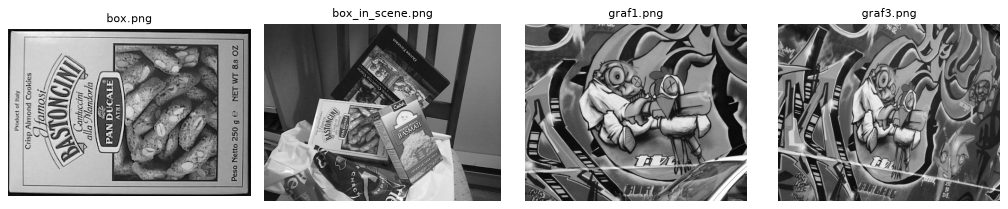

In [4]:
box, fb1 = load_sample("box.png")
scene, fb2 = load_sample("box_in_scene.png")
graf1, fb3 = load_sample("graf1.png")
graf3, fb4 = load_sample("graf3.png")
OFFLINE = fb1 or fb2 or fb3 or fb4
print("box", box.shape, "| scene", scene.shape, "| graf1", graf1.shape, "| graf3", graf3.shape,
      "| офлайн-режим:", OFFLINE)
show(box, scene, graf1, graf3, titles=["box.png", "box_in_scene.png", "graf1.png", "graf3.png"], size=3.2)

### 0.2. Синтетическая пара с известной гомографией

Для честной количественной оценки нужна «истина»: где на втором изображении *должна* оказаться каждая точка
первого. Делаем второе изображение сами: $I_2 = \mathrm{warp}(I_1, H)$, где
$H = T\,P\,S_{\theta,s}$ — поворот на $\theta$ и масштаб $s$ вокруг центра, затем перспективный «наклон» $P$.
Тогда точка $\mathbf{p}_1$ переходит в $\mathbf{p}_2 \sim H\mathbf{p}_1$ (в однородных координатах),
и совпадение $(\mathbf{p}_1, \mathbf{p}_2)$ считаем **верным**, если $\lVert H\mathbf{p}_1 - \mathbf{p}_2\rVert < 3$ px.

Базовое изображение — `graf1`, уменьшенное до 400×320 (чтобы «свой» SIFT на чистом Python работал быстро).
Ко второму изображению добавлен гауссов шум σ = 3 (из 255).

In [5]:
# Код ниже совпадает с siftlab/evaluation.py (вставлен сборщиком tools/build_notebook.py)
def synthetic_homography(w, h, angle=0.0, scale=1.0, persp=(0.0, 0.0), shift=(0.0, 0.0)):
    """Гомография: поворот на angle° и масштаб scale вокруг центра + перспективный
    «наклон» persp=(p1, p2) (в долях 1/размер) + сдвиг. Отображает img1 → img2."""
    cx, cy = (w - 1) / 2, (h - 1) / 2
    A = cv2.getRotationMatrix2D((cx, cy), angle, scale)
    Hs = np.vstack([A, [0, 0, 1]])
    P = np.array([[1, 0, 0], [0, 1, 0], [persp[0] / w, persp[1] / h, 1.0]])
    C = np.array([[1, 0, -cx], [0, 1, -cy], [0, 0, 1]])
    Hp = np.linalg.inv(C) @ P @ C                  # перспектива относительно центра
    Hp /= Hp[2, 2]
    T = np.array([[1, 0, shift[0]], [0, 1, shift[1]], [0, 0, 1]])
    H = T @ Hp @ Hs
    return H / H[2, 2]


def make_pair(img, H, noise=0.0, seed=0):
    """Второе изображение пары: warpPerspective + (опц.) гауссов шум σ=noise (в шкале 0..255)."""
    h, w = img.shape[:2]
    img2 = cv2.warpPerspective(img, H, (w, h), flags=cv2.INTER_LINEAR)
    if noise > 0:
        rng = np.random.default_rng(seed)
        img2 = np.clip(img2 + rng.normal(0, noise, img2.shape), 0, 255).astype(np.uint8)
    return img2

H_gt =
 [[  1.0088   0.3721 -36.992 ]
 [ -0.2865   0.8391 102.1018]
 [  0.0007  -0.0002   1.    ]]


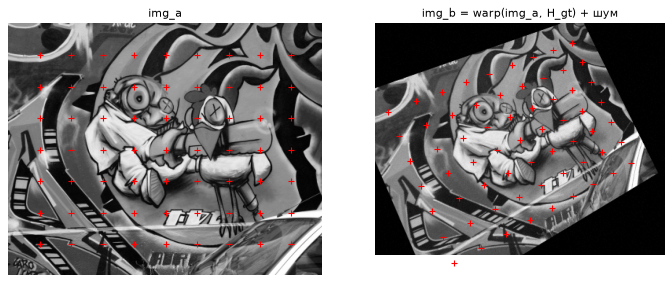

In [6]:
img_a = cv2.resize(graf1, (400, 320), interpolation=cv2.INTER_AREA)
H_gt = synthetic_homography(400, 320, angle=25, scale=0.85, persp=(0.25, -0.15))
img_b = make_pair(img_a, H_gt, noise=3)
print("H_gt =\n", H_gt)

# визуальная проверка: сетка точек img_a, перенесённая в img_b
gx, gy = np.meshgrid(np.linspace(40, 360, 9), np.linspace(40, 280, 7))
grid = np.c_[gx.ravel(), gy.ravel()]
q = np.c_[grid, np.ones(len(grid))] @ H_gt.T
q = q[:, :2] / q[:, 2:]
fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
axs[0].imshow(img_a, cmap="gray"); axs[0].plot(grid[:, 0], grid[:, 1], "r+"); axs[0].set_title("img_a")
axs[1].imshow(img_b, cmap="gray"); axs[1].plot(q[:, 0], q[:, 1], "r+"); axs[1].set_title("img_b = warp(img_a, H_gt) + шум")
for ax in axs: ax.axis("off")
plt.tight_layout(); plt.show()

## 1. Эталон: SIFT из OpenCV

Начнём с готовой реализации — она будет «линейкой» для всех следующих шагов
(см. «Сводка гиперпараметров» в [конспекте](../../rus/SIFT_конспект.md)).

`cv2.SIFT_create(nfeatures, nOctaveLayers, contrastThreshold, edgeThreshold, sigma)`:

| Параметр | По умолчанию | Смысл | В статье |
|---|---|---|---|
| `nfeatures` | 0 (все) | оставить N лучших по `response` | — |
| `nOctaveLayers` | 3 | $s$ — интервалов на октаву, $k = 2^{1/s}$ | $s=3$ (разд. 3.2) |
| `contrastThreshold` | 0.04 | порог $\lvert D(\hat{\mathbf x})\rvert$, **делится на `nOctaveLayers`**: фактически $0.04/3 \approx 0.0133$ | 0.03 (разд. 4) |
| `edgeThreshold` | 10 | $r$ в тесте краёв $\mathrm{Tr}^2/\mathrm{Det} < (r+1)^2/r$ | $r=10$ (разд. 4.1) |
| `sigma` | 1.6 | σ базового уровня октавы | 1.6 (разд. 3.3) |

**Про порог контраста.** OpenCV сравнивает $\lvert D\rvert\cdot s$ с `contrastThreshold`, т.е. эффективный порог
$0.04/s$. Смысл деления: амплитуда DoG пропорциональна $k-1 \approx \ln 2 / s$, поэтому при изменении $s$ порог
масштабируется вместе с откликом. Документация OpenCV советует для «порога из статьи 0.03» ставить
`contrastThreshold=0.09` (тогда $0.09/3 = 0.03$). Порог по умолчанию OpenCV ($\approx 0.0133$) **мягче** статьи
примерно в 2.25 раза → точек больше.

nfeatures = 0 | nOctaveLayers = 3 | contrastThreshold = 0.04 | edgeThreshold = 10.0 | sigma = 1.6


box.png: 604 точек, дескрипторы (604, 128) float32, 23.2 мс


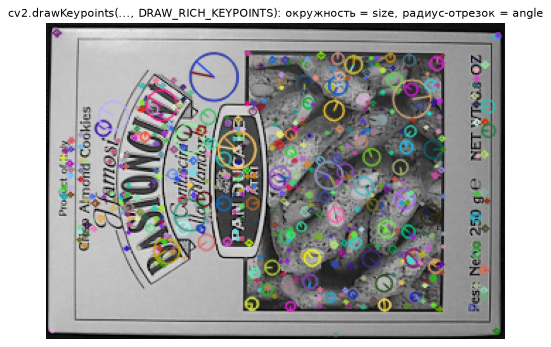

In [7]:
sift_cv = cv2.SIFT_create()
print("nfeatures =", sift_cv.getNFeatures(), "| nOctaveLayers =", sift_cv.getNOctaveLayers(),
      "| contrastThreshold =", sift_cv.getContrastThreshold(), "| edgeThreshold =", sift_cv.getEdgeThreshold(),
      "| sigma =", sift_cv.getSigma())
t = time.perf_counter()
kps_box, des_box = sift_cv.detectAndCompute(box, None)
print(f"box.png: {len(kps_box)} точек, дескрипторы {des_box.shape} {des_box.dtype}, "
      f"{(time.perf_counter() - t) * 1e3:.1f} мс")
vis = cv2.drawKeypoints(box, kps_box, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
show(vis, titles=["cv2.drawKeypoints(..., DRAW_RICH_KEYPOINTS): окружность = size, радиус-отрезок = angle"], size=6)

### 1.1. Поля `cv2.KeyPoint`

* `pt` — $(x, y)$ во входном изображении (субпиксельно);
* `size` — **диаметр** области: $2\sigma$, где $\sigma$ — масштаб точки в пикселях входа;
* `angle` — ориентация в градусах $[0, 360)$, ось $y$ вниз (на экране — по часовой стрелке);
* `response` — $\lvert D(\hat{\mathbf x})\rvert$ (контраст), по нему работает `nfeatures`;
* `octave` — упакованное целое: младший байт — октава со знаком ($-1$ = удвоенное изображение),
  второй байт — слой DoG, третий — $(\hat\xi + 0.5)\cdot 255$, где $\hat\xi$ — дробное смещение по масштабу.

In [8]:
# Код ниже совпадает с siftlab/pipeline.py (вставлен сборщиком tools/build_notebook.py)
def unpack_octave(code):
    """Расшифровка KeyPoint.octave OpenCV: (октава со знаком, слой, xi).
    Младший байт — октава (−1 = удвоенное изображение), второй — слой, третий — (xi+0.5)·255."""
    o = code & 255
    o = o - 256 if o >= 128 else o
    return o, (code >> 8) & 255, ((code >> 16) & 255) / 255.0 - 0.5

                pt   size σ=size/2   angle  response  octave(hex)  (окт, слой, ξ)
( 132.97, 146.54)   2.12     1.06   59.91   0.09238     0xb801ff  (-1, 1, +0.222)
( 132.97, 146.54)   2.12     1.06  275.52   0.09238     0xb801ff  (-1, 1, +0.222)
( 136.63, 117.48)   1.96     0.98   90.69   0.08816     0x5f01ff  (-1, 1, -0.127)
( 137.82, 151.77)   1.89     0.95  266.68   0.08716     0x3801ff  (-1, 1, -0.280)
(  55.95,  92.93)   2.39     1.20  100.51   0.08564     0x3e02ff  (-1, 2, -0.257)
(  55.95,  92.93)   2.39     1.20  278.29   0.08564     0x3e02ff  (-1, 2, -0.257)
( 132.96,  81.25)   2.10     1.05   83.97   0.08522     0xab01ff  (-1, 1, +0.171)
( 132.60, 132.94)   2.37     1.19   37.94   0.08504     0x3502ff  (-1, 2, -0.292)


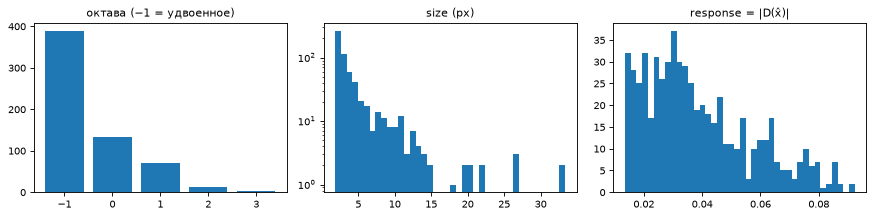

In [9]:
print(f"{'pt':>18} {'size':>6} {'σ=size/2':>8} {'angle':>7} {'response':>9} {'octave(hex)':>12}  (окт, слой, ξ)")
for p in sorted(kps_box, key=lambda p: -p.response)[:8]:
    o, layer, xi = unpack_octave(p.octave)
    print(f"({p.pt[0]:7.2f},{p.pt[1]:7.2f}) {p.size:6.2f} {p.size / 2:8.2f} {p.angle:7.2f} {p.response:9.5f} "
          f"{p.octave:#12x}  ({o:+d}, {layer}, {xi:+.3f})")

oct_ = np.array([unpack_octave(p.octave)[0] for p in kps_box])
fig, axs = plt.subplots(1, 3, figsize=(11, 2.8))
axs[0].hist(oct_, bins=np.arange(oct_.min(), oct_.max() + 2) - 0.5, rwidth=0.8); axs[0].set_title("октава (−1 = удвоенное)")
axs[1].hist([p.size for p in kps_box], bins=40); axs[1].set_title("size (px)"); axs[1].set_yscale("log")
axs[2].hist([p.response for p in kps_box], bins=40); axs[2].set_title("response = |D(x̂)|")
plt.tight_layout(); plt.show()

In [10]:
# Влияние порогов: число точек на box.png
for ct in (0.02, 0.04, 0.09):
    n = len(cv2.SIFT_create(contrastThreshold=ct).detect(box, None))
    print(f"contrastThreshold={ct:<5} (эффективно {ct / 3:.4f}) → {n} точек")
for et in (3, 5, 10, 20):
    n = len(cv2.SIFT_create(edgeThreshold=et).detect(box, None))
    print(f"edgeThreshold={et:<3} → {n} точек")

contrastThreshold=0.02  (эффективно 0.0067) → 657 точек
contrastThreshold=0.04  (эффективно 0.0133) → 604 точек
contrastThreshold=0.09  (эффективно 0.0300) → 372 точек
edgeThreshold=3   → 298 точек
edgeThreshold=5   → 456 точек
edgeThreshold=10  → 604 точек
edgeThreshold=20  → 715 точек


## 2. Масштабное пространство (разд. 3, 3.2, 3.3 [конспекта](../../rus/SIFT_конспект.md))

$$L(x,y,\sigma) = G(x,y,\sigma) * I(x,y),\qquad
D(x,y,\sigma) = L(x,y,k\sigma) - L(x,y,\sigma) \approx (k-1)\,\sigma^2\nabla^2 G * I.$$

Устройство пирамиды (как в статье и OpenCV):

1. **Удвоение.** Вход считается уже размытым с $\sigma_{in}=0.5$; после удвоения билинейной интерполяцией
   размытие становится $1.0$, досглаживаем до $\sigma_0 = 1.6$: $\sigma_{diff} = \sqrt{1.6^2 - 1^2}$.
2. **Октава** — $s+3 = 6$ гауссовых изображений с $\sigma_i = \sigma_0 k^i$, $k = 2^{1/s}$.
   Каждое получается из предыдущего *инкрементальной* свёрткой
   $\sigma_{inc} = \sqrt{\sigma_i^2 - \sigma_{i-1}^2}$ (дисперсии гауссианов складываются).
3. **Следующая октава** начинается с изображения $i=s$ (у него $\sigma = 2\sigma_0$), прореженного в 2 раза.
4. **DoG** — разности соседних уровней: $s+2 = 5$ изображений на октаву; экстремумы ищутся в средних $s=3$.

Число октав, как в OpenCV: $\mathrm{round}(\log_2 \min(H,W) - 2)$ для удвоенного изображения.

In [11]:
# Код ниже совпадает с siftlab/pyramid.py (вставлен сборщиком tools/build_notebook.py)
def to_float01(img):
    """Перевести изображение (uint8, серое или BGR) в float32 серое в диапазоне [0, 1]."""
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img = img.astype(np.float32)
    if img.max() > 1.5:          # uint8-шкала 0..255
        img = img / 255.0
    return img


def base_image(img, sigma=1.6, upsample=True, assumed_blur=0.5):
    """Базовое изображение октавы 0 (разд. 3.3).

    Считается, что вход уже размыт с σ=assumed_blur (0.5). При upsample=True
    изображение удваивается билинейной интерполяцией (как в статье и OpenCV),
    после чего его размытие становится 2·0.5 = 1.0. Досглаживаем до σ:
    σ_diff = sqrt(σ² − σ_имеющееся²).
    """
    img = to_float01(img)
    if upsample:
        h, w = img.shape
        img = cv2.resize(img, (2 * w, 2 * h), interpolation=cv2.INTER_LINEAR)
        sig_diff = np.sqrt(max(sigma ** 2 - (2 * assumed_blur) ** 2, 0.01))
    else:
        sig_diff = np.sqrt(max(sigma ** 2 - assumed_blur ** 2, 0.01))
    return cv2.GaussianBlur(img, (0, 0), sig_diff)


def num_octaves(base_shape, upsample=True):
    """Число октав, как в OpenCV: round(log2(min(H, W)) − 2) + (1, если было удвоение)."""
    return int(round(np.log2(min(base_shape)) - 2)) + (1 if upsample else 0)


def octave_sigmas(s=3, sigma=1.6):
    """Инкрементальные σ для s+3 изображений октавы.

    Полное размытие уровня i: σ_i = σ·k^i, k = 2^(1/s). Каждый следующий уровень
    получается из предыдущего свёрткой с σ_inc = sqrt(σ_i² − σ_{i−1}²)
    (свёртка гауссианов складывает дисперсии). Элемент 0 — σ самого базового уровня.
    """
    k = 2.0 ** (1.0 / s)
    sig = [sigma]
    for i in range(1, s + 3):
        sig_prev = sigma * k ** (i - 1)
        sig_total = sig_prev * k
        sig.append(np.sqrt(sig_total ** 2 - sig_prev ** 2))
    return np.array(sig)


def gaussian_pyramid(base, n_oct, s=3, sigma=1.6):
    """Гауссова пирамида: список октав, каждая — массив (s+3, H_o, W_o) float32.

    Первое изображение октавы o>0 — изображение с индексом s предыдущей октавы
    (его σ = 2σ), прореженное в 2 раза (берём каждый второй пиксель).
    """
    sig = octave_sigmas(s, sigma)
    pyr = []
    for o in range(n_oct):
        if o == 0:
            first = base
        else:
            first = pyr[o - 1][s][::2, ::2]
            # OpenCV: resize(..., Size(cols/2, rows/2), INTER_NEAREST) == срез [::2, ::2]
            h2, w2 = pyr[o - 1][s].shape[0] // 2, pyr[o - 1][s].shape[1] // 2
            first = np.ascontiguousarray(first[:h2, :w2])
        layers = [first]
        for i in range(1, s + 3):
            layers.append(cv2.GaussianBlur(layers[-1], (0, 0), sig[i]))
        pyr.append(np.stack(layers).astype(np.float32))
    return pyr


def dog_pyramid(gpyr):
    """DoG: D_i = L_{i+1} − L_i для каждой октавы → массивы (s+2, H_o, W_o)."""
    return [g[1:] - g[:-1] for g in gpyr]


def build_scale_space(img, s=3, sigma=1.6, upsample=True):
    """Собрать всё масштабное пространство. Возвращает dict с ключами
    gauss, dog, s, sigma, first_octave (−1 при удвоении, иначе 0)."""
    base = base_image(img, sigma, upsample)
    n_oct = num_octaves(base.shape, upsample)
    gpyr = gaussian_pyramid(base, n_oct, s, sigma)
    return dict(gauss=gpyr, dog=dog_pyramid(gpyr), s=s, sigma=sigma,
                first_octave=-1 if upsample else 0)

In [12]:
ss_a = build_scale_space(img_a)
s, sigma0 = ss_a["s"], ss_a["sigma"]
print("инкрементальные σ:", octave_sigmas(s, sigma0).round(4))
print("октав:", len(ss_a["gauss"]))
for o, g in enumerate(ss_a["gauss"]):
    # полное σ уровня i в пикселях ВХОДНОГО изображения: σ0·k^i·2^(o−1)
    sig_abs = sigma0 * 2 ** (np.arange(s + 3) / s) * 2.0 ** (o - 1)
    print(f"  октава {o}: {g.shape[1:]}  σ (px входа) = {sig_abs.round(2)}")

# проверка: инкрементальное размытие == прямое размытие базового уровня
base = ss_a["gauss"][0][0]
direct = cv2.GaussianBlur(base, (0, 0), np.sqrt((sigma0 * 2 ** (5 / 3)) ** 2 - sigma0 ** 2))
print("max |L_5(инкр.) − L_5(прямое)| =", np.abs(ss_a["gauss"][0][5] - direct).max())

инкрементальные σ: [1.6    1.2263 1.545  1.9466 2.4525 3.09  ]
октав: 8
  октава 0: (640, 800)  σ (px входа) = [0.8  1.01 1.27 1.6  2.02 2.54]
  октава 1: (320, 400)  σ (px входа) = [1.6  2.02 2.54 3.2  4.03 5.08]
  октава 2: (160, 200)  σ (px входа) = [ 3.2   4.03  5.08  6.4   8.06 10.16]
  октава 3: (80, 100)  σ (px входа) = [ 6.4   8.06 10.16 12.8  16.13 20.32]
  октава 4: (40, 50)  σ (px входа) = [12.8  16.13 20.32 25.6  32.25 40.64]
  октава 5: (20, 25)  σ (px входа) = [25.6  32.25 40.64 51.2  64.51 81.27]
  октава 6: (10, 12)  σ (px входа) = [ 51.2   64.51  81.27 102.4  129.02 162.55]
  октава 7: (5, 6)  σ (px входа) = [102.4  129.02 162.55 204.8  258.03 325.1 ]
max |L_5(инкр.) − L_5(прямое)| = 1.9907951e-05


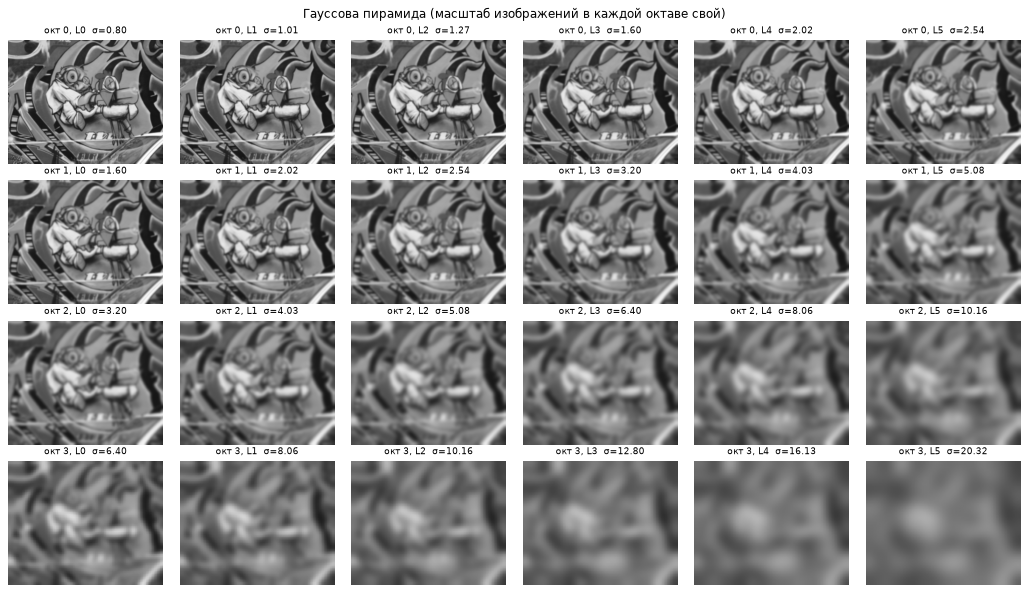

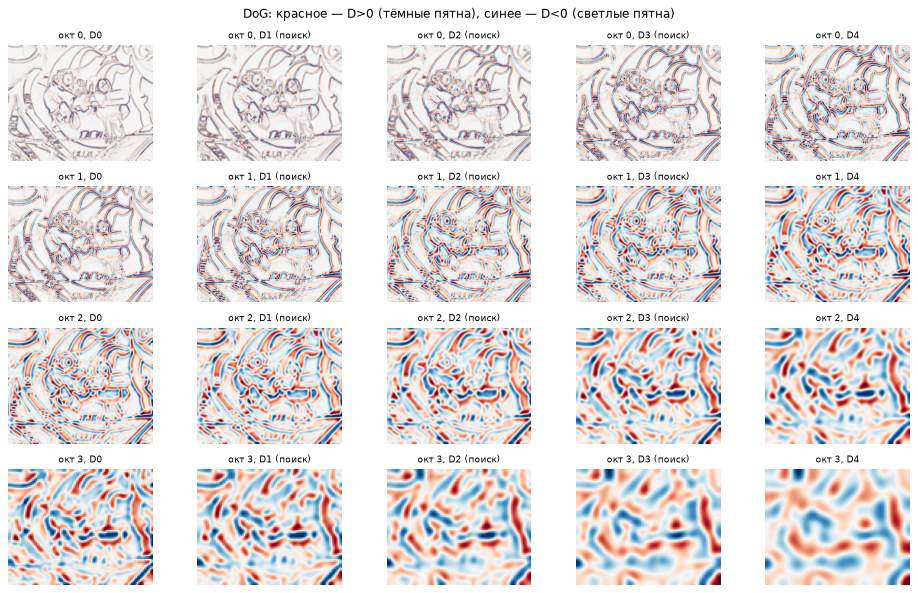

In [13]:
n_show = 4
fig, axs = plt.subplots(n_show, s + 3, figsize=(13, 7.5))
for o in range(n_show):
    for i in range(s + 3):
        axs[o, i].imshow(ss_a["gauss"][o][i], cmap="gray", vmin=0, vmax=1)
        axs[o, i].set_title(f"окт {o}, L{i}  σ={sigma0 * 2 ** (i / s) * 2.0 ** (o - 1):.2f}", fontsize=8)
        axs[o, i].axis("off")
fig.suptitle("Гауссова пирамида (масштаб изображений в каждой октаве свой)")
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(n_show, s + 2, figsize=(12, 7.5))
for o in range(n_show):
    D = ss_a["dog"][o]
    v = np.percentile(np.abs(D), 99.5)
    for i in range(s + 2):
        axs[o, i].imshow(D[i], cmap="RdBu_r", vmin=-v, vmax=v)
        axs[o, i].set_title(f"окт {o}, D{i}" + (" (поиск)" if 1 <= i <= s else ""), fontsize=8)
        axs[o, i].axis("off")
fig.suptitle("DoG: красное — D>0 (тёмные пятна), синее — D<0 (светлые пятна)")
plt.tight_layout(); plt.show()

Разобранный «на числах» пример DoG (ядра, отклик пятна, выбор масштаба) — в [конспекте, разд. 3.0а](../../rus/SIFT_конспект.md)
и скрипте `../../rus/figures/sift/dog_example/dog_example.py`.

OpenCV не отдаёт свою пирамиду наружу, поэтому сверять её будем косвенно — по совпадению найденных точек
(раздел 3) и дескрипторов (раздел 5): если пирамида хоть немного отличается, точного совпадения не будет.

## 3. Детектор (разд. 3.1, 4, 4.1 [конспекта](../../rus/SIFT_конспект.md))

**Шаг 1 — экстремумы.** Отсчёт DoG — кандидат, если он не меньше (не больше) всех 26 соседей: 8 в своём слое и
по 9 в соседних по масштабу. Векторизуем: 26 сдвинутых срезов массива и поэлементные `max`/`min`.
Предварительный порог как в OpenCV: $\lvert D\rvert > 0.5\cdot\text{порог}$ (с округлением в шкале 0..255).

**Шаг 2 — уточнение (формулы (2)–(3)).** Тейлор до 2-го порядка по $\mathbf x = (x, y, \sigma)$:
$$D(\mathbf x) \approx D + \nabla D^\top \mathbf x + \tfrac12 \mathbf x^\top \mathbf H \mathbf x,\qquad
\hat{\mathbf x} = -\mathbf H^{-1}\nabla D .$$
Производные — центральные разности. Если $\lvert\hat x_j\rvert > 0.5$ по любой координате — переходим в соседний
отсчёт и повторяем (не более 5 итераций, иначе отброс).

**Шаг 3 — контраст.** $D(\hat{\mathbf x}) = D + \tfrac12\nabla D^\top\hat{\mathbf x}$; отброс при
$\lvert D(\hat{\mathbf x})\rvert < $ порог (статья: 0.03; OpenCV: $0.04/s \approx 0.0133$).

**Шаг 4 — края.** Гессиан 2×2 по $(x,y)$; при отношении главных кривизн $r$:
$$\frac{\mathrm{Tr}(\mathbf H)^2}{\mathrm{Det}(\mathbf H)} < \frac{(r+1)^2}{r},\quad r = 10,$$
а при $\mathrm{Det} \le 0$ (седло) — отброс.

Уточнение тоже векторизовано: все кандидаты октавы решаются одним вызовом `np.linalg.solve` над стопкой 3×3.

In [14]:
# Код ниже совпадает с siftlab/detector.py (вставлен сборщиком tools/build_notebook.py)
def find_extrema(dog_oct, threshold, border=5):
    """Векторизованный поиск экстремумов по 26 соседям (3×3×3 − 1) в одной октаве.

    dog_oct: (L, H, W). Проверяются слои 1..L−2 (нужны соседи сверху и снизу).
    Условие как в OpenCV: |v| > threshold и v ≥ всех 26 соседей (для максимума)
    или v ≤ всех (для минимума). Возвращает массивы (layer, r, c).
    """
    D = dog_oct
    L, H, W = D.shape
    C = D[1:-1, 1:-1, 1:-1]
    mx = np.full(C.shape, -np.inf, np.float32)
    mn = np.full(C.shape, np.inf, np.float32)
    for dz in (-1, 0, 1):
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                if dz == dy == dx == 0:
                    continue
                nb = D[1 + dz:L - 1 + dz, 1 + dy:H - 1 + dy, 1 + dx:W - 1 + dx]
                np.maximum(mx, nb, out=mx)
                np.minimum(mn, nb, out=mn)
    ext = ((C > threshold) & (C >= mx)) | ((C < -threshold) & (C <= mn))
    # отступ от края (координаты C сдвинуты на 1)
    b = border - 1
    ext[:, :b, :] = False
    ext[:, H - 2 - b:, :] = False
    ext[:, :, :b] = False
    ext[:, :, W - 2 - b:] = False
    l, r, c = np.nonzero(ext)
    return l + 1, r + 1, c + 1


def derivatives(D, l, r, c):
    """Градиент (3,) и гессиан (3×3) DoG конечными разностями в точках (l, r, c).

    Порядок координат (x, y, σ) = (c, r, l). Возвращает g: (n, 3), Hs: (n, 3, 3), v: (n,).
    """
    v = D[l, r, c]
    dx = (D[l, r, c + 1] - D[l, r, c - 1]) * 0.5
    dy = (D[l, r + 1, c] - D[l, r - 1, c]) * 0.5
    ds = (D[l + 1, r, c] - D[l - 1, r, c]) * 0.5
    dxx = D[l, r, c + 1] + D[l, r, c - 1] - 2 * v
    dyy = D[l, r + 1, c] + D[l, r - 1, c] - 2 * v
    dss = D[l + 1, r, c] + D[l - 1, r, c] - 2 * v
    dxy = (D[l, r + 1, c + 1] - D[l, r + 1, c - 1] - D[l, r - 1, c + 1] + D[l, r - 1, c - 1]) * 0.25
    dxs = (D[l + 1, r, c + 1] - D[l + 1, r, c - 1] - D[l - 1, r, c + 1] + D[l - 1, r, c - 1]) * 0.25
    dys = (D[l + 1, r + 1, c] - D[l + 1, r - 1, c] - D[l - 1, r + 1, c] + D[l - 1, r - 1, c]) * 0.25
    g = np.stack([dx, dy, ds], 1).astype(np.float64)
    Hs = np.stack([np.stack([dxx, dxy, dxs], 1),
                   np.stack([dxy, dyy, dys], 1),
                   np.stack([dxs, dys, dss], 1)], 1).astype(np.float64)
    return g, Hs, v


def refine_extrema(D, l, r, c, s=3, contrast_thr=0.04 / 3, edge_r=10.0,
                   border=5, max_iter=5, return_stats=False):
    """Субпиксельное/субмасштабное уточнение (формулы (2)–(3)) + два фильтра.

    x̂ = −H⁻¹·∇D. Если |x̂| > 0.5 по любой координате — переходим в соседний
    отсчёт и повторяем (до max_iter раз). Затем:
      контраст: |D(x̂)| = |D + ½∇Dᵀx̂| < contrast_thr → отброс;
      края:     Tr(H)²/Det(H) ≥ (r+1)²/r или Det ≤ 0 → отброс (гессиан 2×2 по x,y).
    contrast_thr задаётся в шкале яркости [0, 1]. OpenCV использует
    contrastThreshold / nOctaveLayers = 0.04/3 ≈ 0.0133; в статье — 0.03.
    Возвращает dict с массивами l, r, c, xc, xr, xi, contr (и статистику этапов).
    """
    L, H, W = D.shape
    l, r, c = l.copy(), r.copy(), c.copy()
    n = len(l)
    off = np.zeros((n, 3))
    alive = np.ones(n, bool)
    conv = np.zeros(n, bool)
    for it in range(max_iter):
        idx = np.nonzero(alive & ~conv)[0]
        if len(idx) == 0:
            break
        g, Hs, _ = derivatives(D, l[idx], r[idx], c[idx])
        det = np.linalg.det(Hs)
        ok = np.abs(det) > 1e-12
        X = np.zeros_like(g)
        X[ok] = np.linalg.solve(Hs[ok], g[ok][..., None])[..., 0]
        xh = -X                                   # (xc, xr, xi)
        small = np.all(np.abs(xh) < 0.5, 1)
        conv[idx[small]] = True
        off[idx[small]] = xh[small]
        mv = idx[~small]
        step = np.rint(xh[~small])
        huge = np.any(np.abs(xh[~small]) > 1e6, 1)
        alive[mv[huge]] = False
        c[mv] += step[:, 0].astype(int)
        r[mv] += step[:, 1].astype(int)
        l[mv] += step[:, 2].astype(int)
        out = (l[mv] < 1) | (l[mv] > s) | (c[mv] < border) | (c[mv] >= W - border) \
              | (r[mv] < border) | (r[mv] >= H - border)
        alive[mv[out]] = False
    alive &= conv
    n_conv = int(alive.sum())
    idx = np.nonzero(alive)[0]
    g, Hs, v = derivatives(D, l[idx], r[idx], c[idx])
    contr = v + 0.5 * np.sum(g * off[idx], 1)
    keep_c = np.abs(contr) >= contrast_thr
    dxx, dyy, dxy = Hs[:, 0, 0], Hs[:, 1, 1], Hs[:, 0, 1]
    tr = dxx + dyy
    det2 = dxx * dyy - dxy ** 2
    keep_e = (det2 > 0) & (tr ** 2 * edge_r < (edge_r + 1) ** 2 * det2)
    keep = keep_c & keep_e
    idx2 = idx[keep]
    res = dict(l=l[idx2], r=r[idx2], c=c[idx2], xc=off[idx2, 0], xr=off[idx2, 1],
               xi=off[idx2, 2], contr=contr[keep])
    if return_stats:
        res["stats"] = dict(candidates=n, converged=n_conv,
                            after_contrast=int(keep_c.sum()),
                            after_edge=int(keep.sum()))
        # позиции (x, y в пикселях октавы) отброшенных точек — для визуализации
        xy = np.c_[c[idx] + off[idx, 0], r[idx] + off[idx, 1]]
        res["rejected"] = dict(contrast=xy[~keep_c], edge=xy[keep_c & ~keep_e])
    return res


def detect_keypoints(ss, contrast_thr=0.04 / 3, edge_r=10.0, border=5,
                     return_stats=False):
    """Детектор по всем октавам масштабного пространства ss (см. build_scale_space).

    Предварительный порог как в OpenCV: floor(0.5·thr·255)/255 (в шкале uint8).
    Возвращает dict массивов ключевых точек (angle пока не заполнен); при
    return_stats=True — ещё и счётчики этапов и координаты отброшенных точек.
    """
    s, sigma, fo = ss["s"], ss["sigma"], ss["first_octave"]
    pre_thr = np.floor(0.5 * contrast_thr * 255) / 255
    keys = ["x", "y", "octave", "layer", "r", "c", "xi", "sigma_oct", "size", "response"]
    out = {k: [] for k in keys}
    stats = dict(candidates=0, converged=0, after_contrast=0, after_edge=0)
    rejected = dict(contrast=[], edge=[])
    for o, D in enumerate(ss["dog"]):
        if min(D.shape[1:]) <= 2 * border + 2:
            continue
        l, r, c = find_extrema(D, pre_thr, border)
        e = refine_extrema(D, l, r, c, s, contrast_thr, edge_r, border,
                           return_stats=True)
        for k in stats:
            stats[k] += e["stats"][k]
        scale = 2.0 ** (o + fo)                   # пиксель октавы → пиксель входа
        for k in rejected:
            rejected[k].append(e["rejected"][k] * scale)
        sig_oct = sigma * 2.0 ** ((e["l"] + e["xi"]) / s)
        out["x"].append((e["c"] + e["xc"]) * scale)
        out["y"].append((e["r"] + e["xr"]) * scale)
        out["octave"].append(np.full(len(e["l"]), o))
        out["layer"].append(e["l"])
        out["r"].append(e["r"])
        out["c"].append(e["c"])
        out["xi"].append(e["xi"])
        out["sigma_oct"].append(sig_oct)
        out["size"].append(2 * sig_oct * scale)
        out["response"].append(np.abs(e["contr"]))
    kp = {k: np.concatenate(v) if v else np.zeros(0) for k, v in out.items()}
    for k in ("octave", "layer", "r", "c"):
        kp[k] = kp[k].astype(int)
    if return_stats:
        stats["rejected"] = {k: np.concatenate(v) if v else np.zeros((0, 2))
                             for k, v in rejected.items()}
        return kp, stats
    return kp

In [15]:
rows = []
for name, thr in [("OpenCV: 0.04/3", 0.04 / 3), ("статья: 0.03", 0.03)]:
    t = time.perf_counter()
    kp_det, st = detect_keypoints(ss_a, contrast_thr=thr, return_stats=True)
    dt = time.perf_counter() - t
    rows.append((name, st["candidates"], st["converged"], st["after_contrast"], st["after_edge"], dt))
    if thr < 0.02:
        kp_det_cv, st_cv = kp_det, st
print(f"{'порог контраста':<16} {'кандидаты':>10} {'сошлись':>8} {'контраст':>9} {'края':>6} {'время, с':>9}")
for r in rows:
    print(f"{r[0]:<16} {r[1]:>10} {r[2]:>8} {r[3]:>9} {r[4]:>6} {r[5]:>9.2f}")
print("по октавам (порог OpenCV):", np.bincount(kp_det_cv["octave"]))

порог контраста   кандидаты  сошлись  контраст   края  время, с
OpenCV: 0.04/3         2673     2072      1753    913      0.09
статья: 0.03           2314     1802      1198    641      0.08
по октавам (порог OpenCV): [561 246  80  23   3]


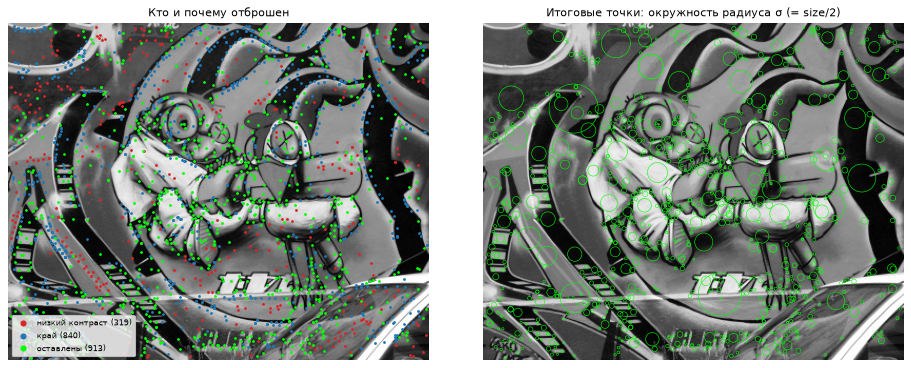

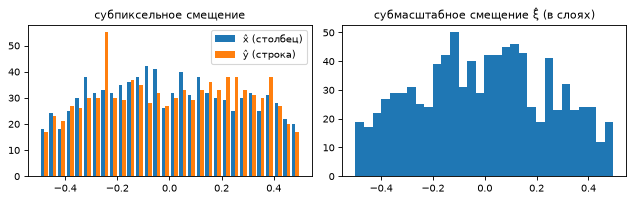

In [16]:
rej = st_cv["rejected"]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
axs[0].imshow(img_a, cmap="gray")
axs[0].plot(rej["contrast"][:, 0], rej["contrast"][:, 1], ".", ms=3, color="tab:red", label=f"низкий контраст ({len(rej['contrast'])})")
axs[0].plot(rej["edge"][:, 0], rej["edge"][:, 1], ".", ms=3, color="tab:blue", label=f"край ({len(rej['edge'])})")
axs[0].plot(kp_det_cv["x"], kp_det_cv["y"], ".", ms=3, color="lime", label=f"оставлены ({len(kp_det_cv['x'])})")
axs[0].legend(loc="lower left", fontsize=7, markerscale=3); axs[0].axis("off")
axs[0].set_title("Кто и почему отброшен")
draw_kps(axs[1], img_a, np.c_[kp_det_cv["x"], kp_det_cv["y"]], kp_det_cv["size"], color="lime", lw=0.5)
axs[1].set_title("Итоговые точки: окружность радиуса σ (= size/2)")
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(8, 2.6))
rcl = detect_keypoints(ss_a, contrast_thr=0.04 / 3)
axs[0].hist(np.c_[rcl["x"] * 2.0 ** -(rcl["octave"] - 1) - rcl["c"], rcl["y"] * 2.0 ** -(rcl["octave"] - 1) - rcl["r"]],
            bins=30, label=["x̂ (столбец)", "ŷ (строка)"]); axs[0].legend(); axs[0].set_title("субпиксельное смещение")
axs[1].hist(rcl["xi"], bins=30); axs[1].set_title("субмасштабное смещение ξ̂ (в слоях)")
plt.tight_layout(); plt.show()

### 3.1. Сравнение с OpenCV

OpenCV возвращает точки уже *после* назначения ориентации (одна точка с двумя ориентациями — две записи),
поэтому сравниваем уникальные позиции. Точка «совпала», если у OpenCV есть точка ближе 2 px с отношением
`size` в $[0.8, 1.25]$.

In [17]:
kps_cv_a, des_cv_a = sift_cv.detectAndCompute(img_a, None)
P_own = np.unique(np.c_[kp_det_cv["x"], kp_det_cv["y"], kp_det_cv["size"]].round(3), axis=0)
P_cv = np.unique(np.array([(*p.pt, p.size) for p in kps_cv_a]).round(3), axis=0)


def nearest(P, Q):
    d2 = (P[:, :1] - Q[:, 0]) ** 2 + (P[:, 1:2] - Q[:, 1]) ** 2
    j = d2.argmin(1)
    return np.sqrt(d2[np.arange(len(P)), j]), j


d_own, j_own = nearest(P_own, P_cv)
ok_own = (d_own < 2) & (np.abs(np.log(P_own[:, 2] / P_cv[j_own, 2])) < np.log(1.25))
d_cv, j_cv = nearest(P_cv, P_own)
ok_cv = (d_cv < 2) & (np.abs(np.log(P_cv[:, 2] / P_own[j_cv, 2])) < np.log(1.25))
print(f"уникальных позиций: свои {len(P_own)}, OpenCV {len(P_cv)}")
print(f"доля своих точек, найденных и OpenCV: {ok_own.mean():.3f};  доля точек OpenCV, найденных нами: {ok_cv.mean():.3f}")
print(f"расхождение координат у совпавших: медиана {np.median(d_own[ok_own]):.2e} px, "
      f"95-й перцентиль {np.percentile(d_own[ok_own], 95):.2e} px, max {d_own[ok_own].max():.2e} px")

уникальных позиций: свои 896, OpenCV 896
доля своих точек, найденных и OpenCV: 1.000;  доля точек OpenCV, найденных нами: 1.000
расхождение координат у совпавших: медиана 0.00e+00 px, 95-й перцентиль 0.00e+00 px, max 1.41e-03 px


Почти полное совпадение не случайно: мы воспроизвели все «невидимые» детали OpenCV — удвоение `INTER_LINEAR`,
досглаживание до σ=1.6 с учётом $\sigma_{in}=0.5$, прореживание `[::2, ::2]`, отступ 5 px от края,
нестрогие неравенства при сравнении с соседями, порядок проверок при итерациях уточнения.
Остаточные расхождения (медиана 0, максимум ~$10^{-3}$ px) — следствие арифметики: OpenCV хранит изображение в шкале 0..255 и решает систему
3×3 в `float32`, мы — в $[0,1]$ и `float64`.

**Замечание о смещении.** `cv2.resize(INTER_LINEAR)` при удвоении сопоставляет пиксель $X$ удвоенного изображения
точке $X/2 - 0.25$ исходного, а координата точки потом просто делится на 2. Поэтому у OpenCV (и у нас) все координаты
сдвинуты примерно на +0.25 px. В OpenCV ≥ 4.8 это лечится флагом `enable_precise_upscale=True`.

## 4. Ориентация (разд. 5 [конспекта](../../rus/SIFT_конспект.md))

В слое $L$ с ближайшим масштабом считаем модуль и направление градиента:
$$m = \sqrt{(L_{x+1,y}-L_{x-1,y})^2 + (L_{x,y+1}-L_{x,y-1})^2},\qquad
\theta = \operatorname{atan2}(L_{x,y+1}-L_{x,y-1},\; L_{x+1,y}-L_{x-1,y}).$$

* Гистограмма из **36 бинов** по 10°, вклад пикселя $= m\cdot \exp\!\big(-\frac{i^2+j^2}{2(1.5\sigma)^2}\big)$, окно радиуса $3\cdot1.5\sigma$.
* Сглаживание круговым ядром $[1,4,6,4,1]/16$ (деталь OpenCV).
* Каждый локальный пик $\ge 80\%$ максимума даёт **отдельную** ключевую точку (в статье — ~15% точек).
* Положение пика уточняется параболой по трём бинам:
  $b^* = b + \tfrac12\,\frac{h_{b-1} - h_{b+1}}{h_{b-1} - 2h_b + h_{b+1}}$.

**Ловушка с осями.** Внутри OpenCV считает $dy = L_{y-1} - L_{y+1}$ (ось $y$ *вверх*), а наружу отдаёт
`angle = 360 − θ` — это то же направление, но в координатах изображения (ось $y$ вниз). Мы делаем ровно так же.

In [18]:
# Код ниже совпадает с siftlab/orientation.py (вставлен сборщиком tools/build_notebook.py)
def gradient_polar(img):
    """Модуль и направление (градусы, ось y ВВЕРХ — как в коде OpenCV) градиента.

    dx = I[y, x+1] − I[y, x−1],  dy = I[y−1, x] − I[y+1, x].
    На крайних пикселях модуль = 0 (OpenCV их пропускает).
    """
    dx = np.zeros_like(img)
    dy = np.zeros_like(img)
    dx[1:-1, 1:-1] = img[1:-1, 2:] - img[1:-1, :-2]
    dy[1:-1, 1:-1] = img[:-2, 1:-1] - img[2:, 1:-1]
    mag = np.sqrt(dx * dx + dy * dy)
    ori = np.degrees(np.arctan2(dy, dx)) % 360.0
    return mag, ori


def gradient_pyramid(gpyr, s=3):
    """Предвычислить (mag, ori) для слоёв 1..s каждой октавы гауссовой пирамиды."""
    return [[gradient_polar(g[i]) if 1 <= i <= s else None for i in range(len(g))]
            for g in gpyr]


def window(mag, ori, r, c, radius):
    """Квадратное окно (2·radius+1)² вокруг (r, c) с обрезкой по краям изображения.

    Возвращает mag, ori окна и смещения i (строки), j (столбцы) каждого пикселя.
    """
    H, W = mag.shape
    r0, r1 = max(r - radius, 0), min(r + radius + 1, H)
    c0, c1 = max(c - radius, 0), min(c + radius + 1, W)
    i, j = np.mgrid[r0 - r:r1 - r, c0 - c:c1 - c]
    return mag[r0:r1, c0:c1], ori[r0:r1, c0:c1], i, j


def orientation_histogram(mag, ori, r, c, sigma_oct, nbins=36):
    """Сглаженная 36-бинная гистограмма ориентаций для точки (r, c) октавы."""
    radius = int(np.rint(4.5 * sigma_oct))      # OpenCV: SIFT_ORI_RADIUS = 3·1.5
    sig = 1.5 * sigma_oct
    m, a, i, j = window(mag, ori, r, c, radius)
    w = np.exp(-(i * i + j * j) / (2 * sig * sig)) * m
    b = np.rint(a * nbins / 360.0).astype(int) % nbins
    hist = np.bincount(b.ravel(), weights=w.ravel(), minlength=nbins)
    # сглаживание круговым ядром [1 4 6 4 1]/16
    hist = (np.roll(hist, 2) + np.roll(hist, -2)) / 16 \
        + (np.roll(hist, 1) + np.roll(hist, -1)) * 4 / 16 + hist * 6 / 16
    return hist


def histogram_peaks(hist, peak_ratio=0.8):
    """Пики ≥ peak_ratio·max, уточнённые параболой. Возвращает углы OpenCV (градусы)."""
    n = len(hist)
    left, right = np.roll(hist, 1), np.roll(hist, -1)
    pk = np.nonzero((hist > left) & (hist > right) & (hist >= peak_ratio * hist.max()))[0]
    den = left[pk] - 2 * hist[pk] + right[pk]
    b = (pk + 0.5 * (left[pk] - right[pk]) / den) % n
    ang = 360.0 - 360.0 / n * b               # перевод «ось y вверх» → «ось y вниз»
    ang[np.abs(ang - 360.0) < 1e-6] = 0.0
    return ang


def assign_orientations(kp, grads, nbins=36, peak_ratio=0.8):
    """Для каждой точки — гистограмма, пики; точка дублируется на каждый пик."""
    rows, angles = [], []
    for k in range(len(kp["x"])):
        mag, ori = grads[kp["octave"][k]][kp["layer"][k]]
        h = orientation_histogram(mag, ori, kp["r"][k], kp["c"][k], kp["sigma_oct"][k], nbins)
        for a in histogram_peaks(h, peak_ratio):
            rows.append(k)
            angles.append(a)
    rows = np.array(rows, int)
    out = {key: v[rows] for key, v in kp.items()}
    out["angle"] = np.array(angles)
    return out

ориентации: 913 → 1117 точек за 0.08 с; доля точек с >1 ориентацией: 0.223


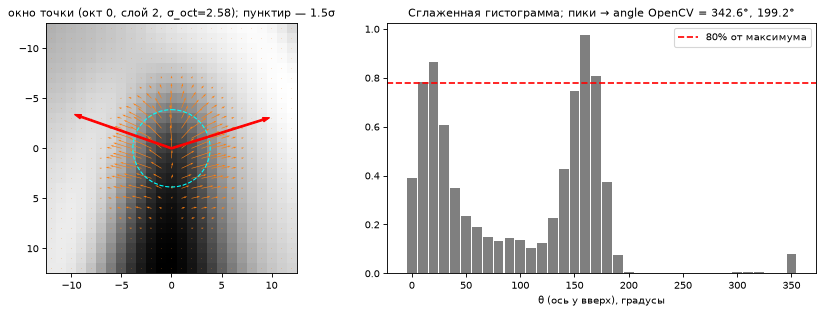

In [19]:
grads_a = gradient_pyramid(ss_a["gauss"], s)
t = time.perf_counter()
kp_ori = assign_orientations(kp_det_cv, grads_a)
print(f"ориентации: {len(kp_det_cv['x'])} → {len(kp_ori['x'])} точек за {time.perf_counter() - t:.2f} с; "
      f"доля точек с >1 ориентацией: {(np.bincount(np.unique(kp_ori['x'], return_inverse=True)[1]) > 1).mean():.3f}")

# одна точка с двумя пиками
cnt = {}
for x in kp_ori["x"]:
    cnt[x] = cnt.get(x, 0) + 1
multi = [k for k in range(len(kp_det_cv["x"])) if cnt.get(kp_det_cv["x"][k], 0) >= 2 and kp_det_cv["sigma_oct"][k] > 2.5]
k = multi[0] if multi else int(np.argmax(kp_det_cv["response"]))
o, l, r, c, so = (kp_det_cv[f][k] for f in ("octave", "layer", "r", "c", "sigma_oct"))
mag, ori = grads_a[o][l]
hist = orientation_histogram(mag, ori, r, c, so)
peaks = histogram_peaks(hist)
rad = int(np.rint(4.5 * so))
m_w, a_w, ii, jj = window(mag, ori, r, c, rad)
G = ss_a["gauss"][o][l]

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].imshow(G[r - rad:r + rad + 1, c - rad:c + rad + 1], cmap="gray",
              extent=(-rad - 0.5, rad + 0.5, rad + 0.5, -rad - 0.5))
wgt = np.exp(-(ii ** 2 + jj ** 2) / (2 * (1.5 * so) ** 2)) * m_w
th = np.radians(a_w)
axs[0].quiver(jj, ii, wgt * np.cos(th), -wgt * np.sin(th), color="tab:orange", angles="xy", scale_units="xy",
              scale=wgt.max() / 2.5)   # −sin: на экране ось y вниз
axs[0].add_patch(Circle((0, 0), 1.5 * so, fill=False, color="cyan", ls="--"))
for a in peaks:
    axs[0].arrow(0, 0, rad * 0.8 * np.cos(np.radians(a)), rad * 0.8 * np.sin(np.radians(a)), color="red", width=0.15)
axs[0].set_title(f"окно точки (окт {o}, слой {l}, σ_oct={so:.2f}); пунктир — 1.5σ")
bins_deg = np.arange(36) * 10
axs[1].bar(bins_deg, hist, width=9, color="tab:gray")
axs[1].axhline(0.8 * hist.max(), color="red", ls="--", label="80% от максимума")
axs[1].set_xlabel("θ (ось y вверх), градусы"); axs[1].legend()
axs[1].set_title("Сглаженная гистограмма; пики → angle OpenCV = " + ", ".join(f"{a:.1f}°" for a in peaks))
plt.tight_layout(); plt.show()

точек с парой в OpenCV: 1117 из 1117; |Δangle|: медиана 1.05e-05°, доля < 0.5°: 0.996
OpenCV: 1094 записей; мы: 1117


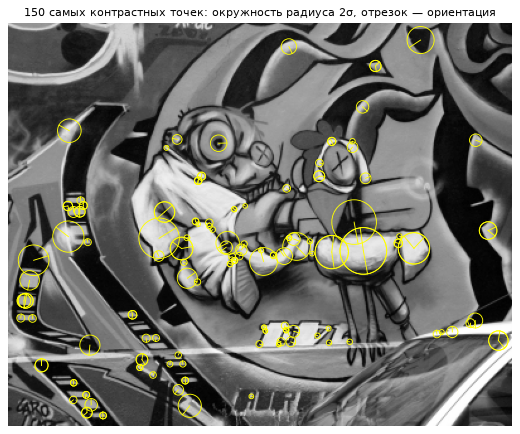

In [20]:
# сравнение углов с OpenCV на совпавших точках
xy_own = np.c_[kp_ori["x"], kp_ori["y"]]
xy_cv = np.array([p.pt for p in kps_cv_a])
ang_cv = np.array([p.angle for p in kps_cv_a])
d2 = ((xy_own[:, None, :] - xy_cv[None]) ** 2).sum(-1)
d2[d2 > 0.01 ** 2] = np.inf                                         # только «те же» точки
dang = np.abs((kp_ori["angle"][:, None] - ang_cv[None] + 180) % 360 - 180) + np.where(np.isfinite(d2), 0, np.inf)
best = dang.min(1)
best = best[np.isfinite(best)]
print(f"точек с парой в OpenCV: {len(best)} из {len(kp_ori['x'])}; |Δangle|: медиана {np.median(best):.2e}°, "
      f"доля < 0.5°: {(best < 0.5).mean():.3f}")
print(f"OpenCV: {len(kps_cv_a)} записей; мы: {len(kp_ori['x'])}")

top = np.argsort(-kp_ori["response"])[:150]
fig, ax = plt.subplots(figsize=(7, 5.5))
draw_kps(ax, img_a, xy_own[top], kp_ori["size"][top] * 2, kp_ori["angle"][top], color="yellow", lw=0.8)
ax.set_title("150 самых контрастных точек: окружность радиуса 2σ, отрезок — ориентация")
plt.tight_layout(); plt.show()

**Почему записей у нас больше, чем у OpenCV?** Иногда два соседних кандидата после уточнения сходятся в одну и ту же
точку (сравните число точек детектора и число уникальных позиций в разделе 3.1). OpenCV удаляет такие дубликаты
(`KeyPointsFilter::removeDuplicatedSorted`), мы сделаем то же в `remove_duplicates` (раздел 5.2) — после этого число
точек совпадёт. Редкие расхождения угла (доли процента) — из-за того, что OpenCV считает угол через `cv::fastAtan2`
(точность ~0.3°) и экспоненту через `cv::exp`: пиксель на границе бина может попасть в соседний бин.

## 5. Дескриптор (разд. 6.1 [конспекта](../../rus/SIFT_конспект.md))

* Окно поворачивается на ориентацию точки: координаты пикселя относительно точки поворачиваются на $-\theta$,
  направления градиентов — тоже ($\theta_{pix} - \theta$).
* Сетка $d\times d = 4\times4$ ячеек, ширина ячейки $3\sigma$ пикселей октавы (константа OpenCV
  `SIFT_DESCR_SCL_FCTR = 3`; в статье — «4×4 отсчёта на масштабе точки»), т.е. окно ≈ $12\sigma$.
* Вклад пикселя $m\cdot w$, $w = \exp\!\big(-\frac{u^2+v^2}{2(d/2)^2}\big)$ ($u,v$ — в ячейках):
  σ гауссиана = **половина ширины окна**.
* **Трилинейная интерполяция**: вклад делится между 2×2 соседними ячейками и 2 соседними бинами ориентации
  с весами $(1-d_r)$/$d_r$ и т.д. — дескриптор не «прыгает» при сдвиге точки на долю ячейки.
* $4\cdot4\cdot8 = 128$ чисел → нормировка к 1 → обрезка компонент на **0.2** (подавление больших градиентов
  от нелинейной освещённости) → повторная нормировка.
* OpenCV в конце умножает на 512 и округляет до `uchar` — функция `to_opencv_scale`.

In [21]:
# Код ниже совпадает с siftlab/descriptor.py (вставлен сборщиком tools/build_notebook.py)
def sift_descriptor(mag, ori, r, c, angle, sigma_oct, d=4, n=8, clip=0.2):
    """Дескриптор одной точки по предвычисленным mag/ori (ось y вверх) слоя октавы.

    r, c — целочисленная позиция в октаве; angle — угол OpenCV (ось y вниз);
    sigma_oct — масштаб точки в пикселях октавы. Возвращает вектор d·d·n единичной нормы.
    """
    H, W = mag.shape
    ori_kp = (360.0 - angle) % 360.0          # обратно в систему «ось y вверх»
    cos_t, sin_t = np.cos(np.radians(ori_kp)), np.sin(np.radians(ori_kp))
    hist_width = 3.0 * sigma_oct              # ширина ячейки в пикселях октавы
    radius = int(np.rint(hist_width * np.sqrt(2) * (d + 1) * 0.5))
    radius = min(radius, int(np.sqrt(H * H + W * W)))
    i, j = np.mgrid[-radius:radius + 1, -radius:radius + 1]
    # поворот смещений в систему координат точки, единица — ширина ячейки
    c_rot = (j * cos_t - i * sin_t) / hist_width
    r_rot = (j * sin_t + i * cos_t) / hist_width
    rbin = r_rot + d / 2 - 0.5
    cbin = c_rot + d / 2 - 0.5
    rr, cc = r + i, c + j
    ok = (rbin > -1) & (rbin < d) & (cbin > -1) & (cbin < d) \
        & (rr > 0) & (rr < H - 1) & (cc > 0) & (cc < W - 1)
    rbin, cbin, rr, cc = rbin[ok], cbin[ok], rr[ok], cc[ok]
    w = np.exp(-(c_rot[ok] ** 2 + r_rot[ok] ** 2) / (d * d * 0.5))  # σ = d/2 ячеек
    m = mag[rr, cc] * w
    obin = (ori[rr, cc] - ori_kp) * (n / 360.0)
    r0, c0, o0 = np.floor(rbin), np.floor(cbin), np.floor(obin)
    fr, fc, fo = rbin - r0, cbin - c0, obin - o0
    r0, c0, o0 = r0.astype(int), c0.astype(int), o0.astype(int) % n
    hist = np.zeros((d + 2) * (d + 2) * (n + 2))
    for dr, wr in ((0, 1 - fr), (1, fr)):
        for dc, wc in ((0, 1 - fc), (1, fc)):
            for do, wo in ((0, 1 - fo), (1, fo)):
                idx = ((r0 + 1 + dr) * (d + 2) + (c0 + 1 + dc)) * (n + 2) + (o0 + do)
                hist += np.bincount(idx, m * wr * wc * wo, minlength=hist.size)
    hist = hist.reshape(d + 2, d + 2, n + 2)
    hist[:, :, 0] += hist[:, :, n]            # круговой перенос по ориентации
    desc = hist[1:d + 1, 1:d + 1, :n].ravel()
    return normalize_clip(desc, clip)


def normalize_clip(v, clip=0.2):
    """Нормировка → обрезка компонент > clip·‖v‖ → повторная нормировка (разд. 6.1)."""
    nrm = np.linalg.norm(v)
    v = np.minimum(v, clip * nrm)
    return (v / max(np.linalg.norm(v), 1e-12)).astype(np.float32)


def compute_descriptors(kp, grads, d=4, n=8, clip=0.2):
    """Дескрипторы для всех точек kp (нужны поля octave, layer, r, c, angle, sigma_oct)."""
    out = np.zeros((len(kp["x"]), d * d * n), np.float32)
    for k in range(len(kp["x"])):
        mag, ori = grads[kp["octave"][k]][kp["layer"][k]]
        out[k] = sift_descriptor(mag, ori, kp["r"][k], kp["c"][k], kp["angle"][k],
                                 kp["sigma_oct"][k], d, n, clip)
    return out


def to_opencv_scale(desc):
    """Перевод в шкалу OpenCV: ×512, округление и насыщение до 255 (как uchar)."""
    return np.clip(np.rint(desc * 512.0), 0, 255).astype(np.float32)


def root_sift(desc, eps=1e-12):
    """RootSIFT (Arandjelović & Zisserman, 2012): L1-нормировка и поэлементный корень.
    Евклидово расстояние между RootSIFT ≈ ядро Хеллингера между исходными SIFT."""
    desc = desc / (np.abs(desc).sum(1, keepdims=True) + eps)
    return np.sqrt(desc).astype(np.float32)

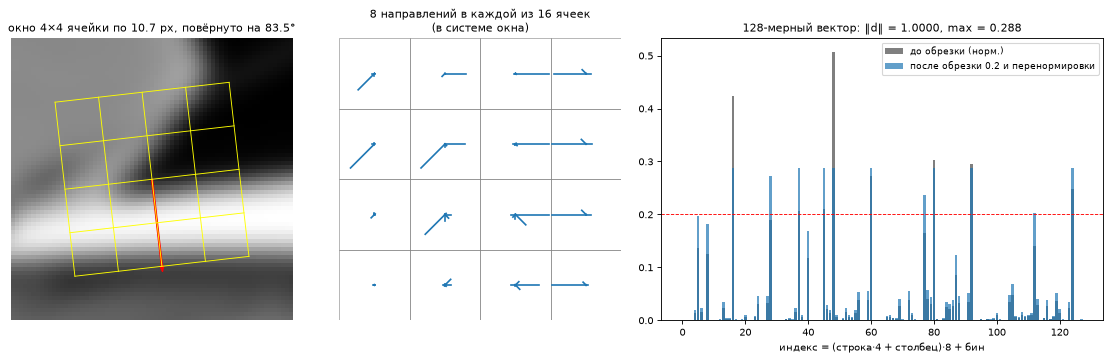

In [22]:
# дескриптор одной точки: окно на изображении октавы и 4×4 «розы» направлений
k = int(np.argmax(kp_ori["sigma_oct"] * (kp_ori["response"] > np.median(kp_ori["response"]))))
o, l, r, c, so, ang = (kp_ori[f][k] for f in ("octave", "layer", "r", "c", "sigma_oct", "angle"))
mag, ori = grads_a[o][l]
d_raw = sift_descriptor(mag, ori, r, c, ang, so, clip=1.0)   # clip=1 → без обрезки
d_fin = sift_descriptor(mag, ori, r, c, ang, so)

G = ss_a["gauss"][o][l]
hw = 3 * so
a = np.radians(ang)
ex, ey = np.array([np.cos(a), np.sin(a)]), np.array([-np.sin(a), np.cos(a)])   # оси окна (ось y вниз)
fig, axs = plt.subplots(1, 3, figsize=(14, 4.4), gridspec_kw=dict(width_ratios=[1, 1, 1.5]))
R = int(hw * 3.2)
axs[0].imshow(G[r - R:r + R + 1, c - R:c + R + 1], cmap="gray", extent=(c - R - .5, c + R + .5, r + R + .5, r - R - .5))
for t_ in np.linspace(-2, 2, 5) * hw:
    for u0, u1 in ((ex * t_ - ey * 2 * hw, ex * t_ + ey * 2 * hw), (ey * t_ - ex * 2 * hw, ey * t_ + ex * 2 * hw)):
        axs[0].plot([c + u0[0], c + u1[0]], [r + u0[1], r + u1[1]], color="yellow", lw=0.8)
axs[0].arrow(c, r, *(ex * 2 * hw), color="red", width=0.3)
axs[0].set_title(f"окно 4×4 ячейки по {hw:.1f} px, повёрнуто на {ang:.1f}°")
axs[0].axis("off")
# розы: бин b — направление ang + 45°·b относительно оси окна (в системе «ось y вверх» углы идут против часовой)
H8 = d_fin.reshape(4, 4, 8)
axs[1].set_xlim(-0.5, 3.5); axs[1].set_ylim(3.5, -0.5); axs[1].set_aspect("equal")
for i in range(4):
    for j in range(4):
        axs[1].add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, fill=False, color="gray", lw=0.5))
        for b in range(8):
            phi = np.radians(45 * b)
            L_ = H8[i, j, b] / H8.max() * 0.48
            axs[1].plot([j, j + L_ * np.cos(phi)], [i, i - L_ * np.sin(phi)], color="tab:blue", lw=1.5)
axs[1].set_title("8 направлений в каждой из 16 ячеек\n(в системе окна)"); axs[1].axis("off")
axs[2].bar(np.arange(128), d_raw, color="tab:gray", label="до обрезки (норм.)")
axs[2].bar(np.arange(128), d_fin, color="tab:blue", alpha=0.7, label="после обрезки 0.2 и перенормировки")
axs[2].axhline(0.2, color="red", ls="--", lw=0.8)
axs[2].set_xlabel("индекс = (строка·4 + столбец)·8 + бин"); axs[2].legend(fontsize=8)
axs[2].set_title(f"128-мерный вектор: ‖d‖ = {np.linalg.norm(d_fin):.4f}, max = {d_fin.max():.3f}")
plt.tight_layout(); plt.show()

### 5.1. Ключевой тест: свой дескриптор на точках OpenCV

Чтобы проверить *только* дескриптор (без влияния детектора), берём ключевые точки OpenCV, восстанавливаем по полю
`octave` номер октавы/слоя, позицию в октаве $\mathbf{p}/2^{o}$ и масштаб $\sigma_{oct} = \tfrac12\,\mathrm{size}/2^{o}$,
и считаем наш дескриптор на нашей пирамиде. Сравниваем с `des` из `sift_cv.compute` косинусной близостью.

In [23]:
# Код ниже совпадает с siftlab/pipeline.py (вставлен сборщиком tools/build_notebook.py)
def kp_from_cv(kps, s=3, sigma=1.6, first_octave=-1):
    """Список cv2.KeyPoint → dict массивов в нашем формате (для расчёта своих дескрипторов
    на точках OpenCV). Позиция в октаве = pt / 2^o, масштаб σ_oct = size/2 / 2^o."""
    cols = {k: [] for k in ["x", "y", "octave", "layer", "r", "c", "xi",
                            "sigma_oct", "size", "response", "angle"]}
    for p in kps:
        o, layer, xi = unpack_octave(p.octave)
        sc = 2.0 ** (-o)
        cols["x"].append(p.pt[0]); cols["y"].append(p.pt[1])
        cols["octave"].append(o - first_octave); cols["layer"].append(layer)
        cols["r"].append(int(np.rint(p.pt[1] * sc))); cols["c"].append(int(np.rint(p.pt[0] * sc)))
        cols["xi"].append(xi); cols["sigma_oct"].append(p.size * sc * 0.5)
        cols["size"].append(p.size); cols["response"].append(p.response)
        cols["angle"].append(p.angle)
    kp = {k: np.array(v) for k, v in cols.items()}
    for k in ("octave", "layer", "r", "c"):
        kp[k] = kp[k].astype(int)
    return kp

1094 точек, 0.33 с (0.31 мс/точку)
косинусная близость: среднее 0.999983, медиана 0.999982, 1-й перцентиль 0.999977, min 0.999974
в шкале OpenCV (uchar): доля дескрипторов, совпавших с точностью ±1: 1.0000; доля точно равных компонент: 0.9991


  правильно                                     медиана cos = 1.0000
  угол без перевода 360−θ (знак поворота)       медиана cos = 0.3883
  σ = size/2^o (забыли /2: size — диаметр)      медиана cos = 0.7152
  без поворота окна (angle = 0)                 медиана cos = 0.3794
  соседний слой (не тот уровень пирамиды)       медиана cos = 0.9880


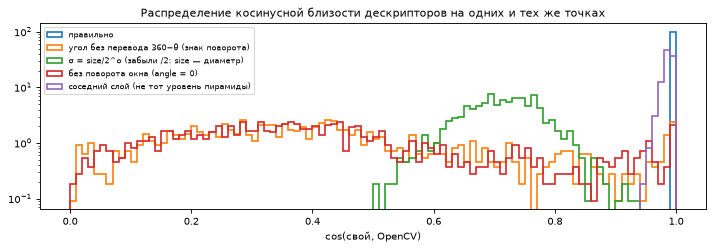

In [24]:
kp_cvfmt = kp_from_cv(kps_cv_a, s, sigma0, ss_a["first_octave"])
t = time.perf_counter()
d_own_on_cv = compute_descriptors(kp_cvfmt, grads_a)
t_desc = time.perf_counter() - t
d_cv_n = des_cv_a / np.linalg.norm(des_cv_a, axis=1, keepdims=True)
cos_sim = (d_own_on_cv * d_cv_n).sum(1)
diff255 = np.abs(to_opencv_scale(d_own_on_cv) - des_cv_a)
print(f"{len(kps_cv_a)} точек, {t_desc:.2f} с ({t_desc / len(kps_cv_a) * 1e3:.2f} мс/точку)")
print(f"косинусная близость: среднее {cos_sim.mean():.6f}, медиана {np.median(cos_sim):.6f}, "
      f"1-й перцентиль {np.percentile(cos_sim, 1):.6f}, min {cos_sim.min():.6f}")
print(f"в шкале OpenCV (uchar): доля дескрипторов, совпавших с точностью ±1: {np.all(diff255 <= 1, 1).mean():.4f}; "
      f"доля точно равных компонент: {(diff255 == 0).mean():.4f}")

# Типичные ошибки при переносе дескриптора — что будет, если ошибиться в соглашениях
def variant(**ch):
    kp2 = dict(kp_cvfmt)
    kp2.update(ch)
    return (compute_descriptors(kp2, grads_a) * d_cv_n).sum(1)


variants = {
    "правильно": cos_sim,
    "угол без перевода 360−θ (знак поворота)": variant(angle=(360 - kp_cvfmt["angle"]) % 360),
    "σ = size/2^o (забыли /2: size — диаметр)": variant(sigma_oct=kp_cvfmt["sigma_oct"] * 2),
    "без поворота окна (angle = 0)": variant(angle=np.zeros(len(kp_cvfmt["angle"]))),
    "соседний слой (не тот уровень пирамиды)": variant(layer=np.where(kp_cvfmt["layer"] < s, kp_cvfmt["layer"] + 1, kp_cvfmt["layer"] - 1)),
}
fig, ax = plt.subplots(figsize=(9, 3.2))
for name, v in variants.items():
    print(f"  {name:<45} медиана cos = {np.median(v):.4f}")
    ax.hist(v, bins=np.linspace(0, 1, 101), histtype="step", lw=1.5, label=name, density=True)
ax.set_yscale("log"); ax.set_xlabel("cos(свой, OpenCV)"); ax.legend(fontsize=7, loc="upper left")
ax.set_title("Распределение косинусной близости дескрипторов на одних и тех же точках")
plt.tight_layout(); plt.show()

Результат — практически побитовое совпадение (расхождение не больше 1 уровня `uchar` из-за `fastAtan2` и округления).
Ошибки в соглашениях (знак угла, «диаметр vs радиус», уровень пирамиды) сразу видны по падению близости —
это хороший способ отлаживать собственную реализацию.

**Сопоставление на одних и тех же точках.** Проверим, что наш дескриптор не хуже и в деле: на синтетической паре
берём точки OpenCV в обоих изображениях и сопоставляем (одним и тем же `cv2.BFMatcher`, ratio 0.8) дескрипторы OpenCV
и наши. Верность — по истинной гомографии.

In [25]:
kps_cv_b, des_cv_b = sift_cv.detectAndCompute(img_b, None)
ss_b = build_scale_space(img_b)
grads_b = gradient_pyramid(ss_b["gauss"], s)
d_own_on_cv_b = compute_descriptors(kp_from_cv(kps_cv_b), grads_b)
pa = np.array([p.pt for p in kps_cv_a]); pb = np.array([p.pt for p in kps_cv_b])
bf = cv2.BFMatcher(cv2.NORM_L2)
for name, DA, DB in [("дескрипторы OpenCV", des_cv_a, des_cv_b), ("наши дескрипторы", d_own_on_cv, d_own_on_cv_b)]:
    mm = [m for m, n in bf.knnMatch(DA.astype(np.float32), DB.astype(np.float32), k=2) if m.distance < 0.8 * n.distance]
    q = np.c_[pa[[m.queryIdx for m in mm]], np.ones(len(mm))] @ H_gt.T
    err = np.linalg.norm(q[:, :2] / q[:, 2:] - pb[[m.trainIdx for m in mm]], axis=1)
    print(f"{name:<20}: {len(mm)} совпадений после ratio 0.8, верных {np.sum(err < 3)} (precision {np.mean(err < 3):.3f})")

дескрипторы OpenCV  : 582 совпадений после ratio 0.8, верных 546 (precision 0.938)
наши дескрипторы    : 582 совпадений после ratio 0.8, верных 546 (precision 0.938)


### 5.2. Сборка конвейера

Склеиваем шаги 2–5 в одну функцию `sift_detect_and_compute` — аналог `sift.detectAndCompute`. Как и OpenCV,
удаляем точные дубликаты и (опционально) оставляем `n_features` точек с наибольшим откликом.

In [26]:
# Код ниже совпадает с siftlab/pipeline.py (вставлен сборщиком tools/build_notebook.py)
def remove_duplicates(kp):
    """Удалить точные дубликаты (x, y, size, angle) — аналог KeyPointsFilter::removeDuplicated."""
    key = np.round(np.c_[kp["x"], kp["y"], kp["size"], kp["angle"]], 4)
    _, first = np.unique(key, axis=0, return_index=True)
    first = np.sort(first)
    return {k: v[first] for k, v in kp.items()}


def top_n(kp, n):
    """Оставить n точек с наибольшим откликом |D(x̂)| (аналог nfeatures в OpenCV)."""
    if n is None or n <= 0 or len(kp["x"]) <= n:
        return kp
    order = np.argsort(-kp["response"], kind="stable")[:n]
    return {k: v[order] for k, v in kp.items()}


def sift_detect_and_compute(img, n_features=0, s=3, sigma=1.6,
                            contrast_thr=0.04 / 3, edge_r=10.0):
    """Свой SIFT целиком: пирамида → детектор → ориентации → дескрипторы.
    Возвращает (kp: dict массивов, desc: (n, 128) float32 единичной нормы)."""
    ss = build_scale_space(img, s, sigma)
    kp = detect_keypoints(ss, contrast_thr, edge_r)
    grads = gradient_pyramid(ss["gauss"], s)
    kp = assign_orientations(kp, grads)
    kp = top_n(remove_duplicates(kp), n_features)
    desc = compute_descriptors(kp, grads)
    return kp, desc


def kp_to_cv(kp, first_octave=-1):
    """dict массивов → список cv2.KeyPoint (octave закодирован как в OpenCV)."""
    res = []
    for k in range(len(kp["x"])):
        xi = kp["xi"][k]
        o = int(kp["octave"][k]) + first_octave
        code = (o & 255) | (int(kp["layer"][k]) << 8) | (int(np.rint((xi + 0.5) * 255)) << 16)
        res.append(cv2.KeyPoint(float(kp["x"][k]), float(kp["y"][k]), float(kp["size"][k]),
                                float(kp["angle"][k]), float(kp["response"][k]), code))
    return res


def kp_xy(kps):
    """Координаты (n, 2) из списка cv2.KeyPoint или из нашего dict."""
    if isinstance(kps, dict):
        return np.c_[kps["x"], kps["y"]]
    return np.array([p.pt for p in kps], float).reshape(-1, 2)

In [27]:
t = time.perf_counter()
kp_a, d_a = sift_detect_and_compute(img_a)
t_own = time.perf_counter() - t
t = time.perf_counter()
kps_tmp, _ = sift_cv.detectAndCompute(img_a, None)
t_cv = time.perf_counter() - t
print(f"свой SIFT: {len(kp_a['x'])} точек за {t_own:.2f} с;  OpenCV: {len(kps_tmp)} точек за {t_cv * 1e3:.0f} мс "
      f"(в {t_own / t_cv:.0f} раз быстрее — C++ и SIMD)")

свой SIFT: 1094 точек за 0.67 с;  OpenCV: 1094 точек за 23 мс (в 29 раз быстрее — C++ и SIMD)


## 6. Сопоставление (разд. 7.1–7.2 [конспекта](../../rus/SIFT_конспект.md))

**Полный перебор.** Квадраты расстояний между всеми парами — одним матричным умножением:
$$\lVert \mathbf a - \mathbf b\rVert^2 = \lVert\mathbf a\rVert^2 + \lVert\mathbf b\rVert^2 - 2\,\mathbf a^\top\mathbf b .$$

**Тест отношения (ratio test).** Принимаем ближайшего соседа, только если он заметно ближе второго:
$d_1/d_2 < 0.8$. Второй сосед оценивает «плотность ложных совпадений» в этой области пространства дескрипторов
(рис. 11 статьи: отсекает ~90% ложных и <5% верных).

**Взаимная проверка (cross-check).** $i\to j$ и $j \to i$ должны быть ближайшими друг для друга.

In [28]:
# Код ниже совпадает с siftlab/matching.py (вставлен сборщиком tools/build_notebook.py)
def l2_distances(A, B):
    """Матрица евклидовых расстояний через ‖a‖² + ‖b‖² − 2·a·b (одно матричное умножение)."""
    A = A.astype(np.float32)
    B = B.astype(np.float32)
    d2 = (A * A).sum(1)[:, None] + (B * B).sum(1)[None, :] - 2.0 * (A @ B.T)
    return np.sqrt(np.maximum(d2, 0.0))


def knn2(A, B, block=2048):
    """Два ближайших соседа из B для каждой строки A. Возвращает idx (n,2), dist (n,2).
    Считаем блоками, чтобы матрица расстояний не занимала много памяти."""
    idx = np.zeros((len(A), 2), int)
    dist = np.zeros((len(A), 2), np.float32)
    for s in range(0, len(A), block):
        Dm = l2_distances(A[s:s + block], B)
        top = np.argpartition(Dm, 1, axis=1)[:, :2]
        dt = np.take_along_axis(Dm, top, 1)
        order = np.argsort(dt, 1)
        idx[s:s + block] = np.take_along_axis(top, order, 1)
        dist[s:s + block] = np.take_along_axis(dt, order, 1)
    return idx, dist


def ratio_match(A, B, ratio=0.8):
    """Тест отношения Лоу: принять NN, если d1/d2 < ratio.
    Возвращает matches (m, 2) пар индексов (i в A, j в B), отношения всех точек и knn."""
    idx, dist = knn2(A, B)
    r = dist[:, 0] / np.maximum(dist[:, 1], 1e-12)
    keep = r < ratio
    matches = np.stack([np.nonzero(keep)[0], idx[keep, 0]], 1)
    return matches, r, idx, dist


def mutual_match(A, B):
    """Взаимно ближайшие соседи (аналог BFMatcher(crossCheck=True))."""
    Dm = l2_distances(A, B)
    ab = Dm.argmin(1)
    ba = Dm.argmin(0)
    i = np.nonzero(ba[ab] == np.arange(len(A)))[0]
    return np.stack([i, ab[i]], 1)

In [29]:
kp_b, d_b = sift_detect_and_compute(img_b)
p_a, p_b = kp_xy(kp_a), kp_xy(kp_b)
print(f"img_a: {len(p_a)} точек, img_b: {len(p_b)} точек")

# 1) корректность: сравнение с наивным перебором и с cv2.BFMatcher
idx, dist = knn2(d_a, d_b)
naive = np.array([np.argsort([np.linalg.norm(d_a[i] - d_b[j]) for j in range(len(d_b))])[:2] for i in range(50)])
print("совпадение с наивным перебором (50 строк):", np.array_equal(naive, idx[:50]))
knn_cv = bf.knnMatch(d_a, d_b, k=2)
same = np.mean([m.trainIdx == idx[i, 0] and n.trainIdx == idx[i, 1] for i, (m, n) in enumerate(knn_cv)])
print(f"совпадение (1-й и 2-й сосед) с cv2.BFMatcher.knnMatch: {same:.4f};  "
      f"max |Δd1| = {np.max(np.abs(dist[:, 0] - [m.distance for m, n in knn_cv])):.2e}")

img_a: 1094 точек, img_b: 1030 точек
совпадение с наивным перебором (50 строк): True
совпадение (1-й и 2-й сосед) с cv2.BFMatcher.knnMatch: 1.0000;  max |Δd1| = 3.95e-06


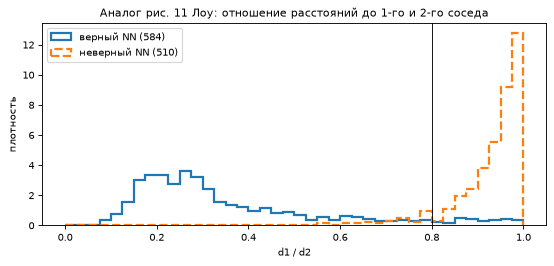

порог 0.8 отбрасывает 92.9% неверных и 6.5% верных


In [30]:
# 2) аналог рис. 11 статьи: распределение d1/d2 для верных и неверных ближайших соседей
from_gt = np.c_[p_a, np.ones(len(p_a))] @ H_gt.T
from_gt = from_gt[:, :2] / from_gt[:, 2:]
nn_correct = np.linalg.norm(from_gt - p_b[idx[:, 0]], axis=1) < 3
ratio = dist[:, 0] / dist[:, 1]
bins = np.linspace(0, 1, 41)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(ratio[nn_correct], bins, density=True, histtype="step", lw=2, label=f"верный NN ({nn_correct.sum()})")
ax.hist(ratio[~nn_correct], bins, density=True, histtype="step", lw=2, ls="--", label=f"неверный NN ({(~nn_correct).sum()})")
ax.axvline(0.8, color="k", lw=0.8)
ax.set_xlabel("d1 / d2"); ax.set_ylabel("плотность"); ax.legend()
ax.set_title("Аналог рис. 11 Лоу: отношение расстояний до 1-го и 2-го соседа")
plt.tight_layout(); plt.show()
print(f"порог 0.8 отбрасывает {np.mean(ratio[~nn_correct] >= 0.8):.1%} неверных и {np.mean(ratio[nn_correct] >= 0.8):.1%} верных")

In [31]:
# 3) стратегии отбора: NN / ratio / cross-check
def report(name, M):
    ok = np.linalg.norm(from_gt[M[:, 0]] - p_b[M[:, 1]], axis=1) < 3
    print(f"{name:<24} совпадений {len(M):5d}, верных {ok.sum():5d}, precision {ok.mean():.3f}")


report("ближайший сосед", np.c_[np.arange(len(d_a)), idx[:, 0]])
M_ratio, _, _, _ = ratio_match(d_a, d_b, 0.8)
report("ratio 0.8", M_ratio)
M_mut = mutual_match(d_a, d_b)
report("cross-check", M_mut)
both = np.array(sorted(set(map(tuple, M_ratio)) & set(map(tuple, M_mut)))).reshape(-1, 2)
report("ratio 0.8 + cross-check", both)

ближайший сосед          совпадений  1094, верных   584, precision 0.534
ratio 0.8                совпадений   582, верных   546, precision 0.938
cross-check              совпадений   623, верных   553, precision 0.888
ratio 0.8 + cross-check  совпадений   539, верных   525, precision 0.974


In [32]:
# 4) скорость: свой перебор, cv2.BFMatcher, FLANN (KD-деревья) — на увеличенном наборе
rep = 4                                             # «база» побольше: дескрипторы с шумом
A = d_a
B = np.vstack([d_b] + [d_b + np.random.default_rng(i).normal(0, 0.02, d_b.shape).astype(np.float32) for i in range(rep - 1)])
t = time.perf_counter(); i_own, _ = knn2(A, B); t_own = time.perf_counter() - t
t = time.perf_counter(); k_bf = bf.knnMatch(A, B, k=2); t_bf = time.perf_counter() - t
flann = cv2.FlannBasedMatcher(dict(algorithm=1, trees=5), dict(checks=50))   # 1 = FLANN_INDEX_KDTREE
t = time.perf_counter(); k_fl = flann.knnMatch(A, B, k=2); t_fl = time.perf_counter() - t
agree_bf = np.mean([m.trainIdx == i_own[q, 0] for q, (m, n) in enumerate(k_bf)])
agree_fl = np.mean([m.trainIdx == i_own[q, 0] for q, (m, n) in enumerate(k_fl)])
print(f"запросов {len(A)}, база {len(B)}")
print(f"свой numpy-перебор : {t_own * 1e3:7.1f} мс")
print(f"cv2.BFMatcher      : {t_bf * 1e3:7.1f} мс, тот же 1-й сосед: {agree_bf:.4f}")
print(f"FLANN KD-tree      : {t_fl * 1e3:7.1f} мс, тот же 1-й сосед: {agree_fl:.4f} (приближённый поиск, ср. BBF в разд. 7.2)")

запросов 1094, база 4120
свой numpy-перебор :    71.9 мс
cv2.BFMatcher      :    19.0 мс, тот же 1-й сосед: 1.0000
FLANN KD-tree      :    48.2 мс, тот же 1-й сосед: 0.7660 (приближённый поиск, ср. BBF в разд. 7.2)


## 7. Геометрическая проверка: RANSAC + гомография

В статье (разд. 7.3–7.4) Лоу кластеризует совпадения преобразованием Хафа и решает аффинную задачу МНК.
Для плоских сцен и для визуального позиционирования сегодня стандарт — **RANSAC** с гомографией
(см. [RANSAC_конспект](../../rus/RANSAC_конспект.md)).

**Нормализованный DLT.** Для пары $\mathbf p \leftrightarrow \mathbf p'$ из $\mathbf p' \times H\mathbf p = 0$
получаем две строки матрицы $A$ (2n×9); $\mathbf h$ — правый сингулярный вектор $A$ с наименьшим
сингулярным числом. Перед этим точки нормируются (Хартли): центр в 0, среднее расстояние $\sqrt2$ —
без этого задача плохо обусловлена.

**RANSAC.** Повторяем: случайные 4 пары → $H$ → inlier'ы с ошибкой $\lVert H\mathbf p - \mathbf p'\rVert < 3$ px.
Число итераций адаптивно:
$$N = \frac{\log(1-p)}{\log(1-w^4)},$$
$w$ — доля inlier'ов лучшей гипотезы, $p = 0.99$. В конце $H$ переоценивается по всем inlier'ам.

In [33]:
# Код ниже совпадает с siftlab/geometry.py (вставлен сборщиком tools/build_notebook.py)
def project(H, p):
    """Применить гомографию H (3×3) к точкам p (n, 2)."""
    q = np.c_[p, np.ones(len(p))] @ H.T
    return q[:, :2] / q[:, 2:3]


def normalize_points(p):
    """Нормировка Хартли: центр масс в 0, среднее расстояние до центра √2. Возвращает (p', T)."""
    m = p.mean(0)
    sc = np.sqrt(2) / max(np.mean(np.linalg.norm(p - m, axis=1)), 1e-12)
    T = np.array([[sc, 0, -sc * m[0]], [0, sc, -sc * m[1]], [0, 0, 1]])
    return (p - m) * sc, T


def dlt_homography(p1, p2):
    """Нормализованный DLT: H такая, что p2 ~ H·p1. Нужно ≥ 4 пар; при n > 4 — МНК (SVD)."""
    a, T1 = normalize_points(p1)
    b, T2 = normalize_points(p2)
    n = len(a)
    A = np.zeros((2 * n, 9))
    x, y, u, v = a[:, 0], a[:, 1], b[:, 0], b[:, 1]
    A[0::2, 0:3] = np.c_[-x, -y, -np.ones(n)]
    A[0::2, 6:9] = np.c_[u * x, u * y, u]
    A[1::2, 3:6] = np.c_[-x, -y, -np.ones(n)]
    A[1::2, 6:9] = np.c_[v * x, v * y, v]
    _, _, Vt = np.linalg.svd(A)
    Hn = Vt[-1].reshape(3, 3)
    H = np.linalg.inv(T2) @ Hn @ T1
    return H / H[2, 2] if abs(H[2, 2]) > 1e-12 else H


def ransac_homography(p1, p2, thr=3.0, conf=0.99, max_iter=2000, seed=0):
    """RANSAC для гомографии с адаптивным числом итераций.

    N = log(1 − p) / log(1 − w⁴), где w — доля inlier'ов лучшей гипотезы.
    После поиска — переоценка H по всем inlier'ам (DLT-МНК) и пересчёт inlier'ов.
    Возвращает H, маску inlier'ов, число выполненных итераций.
    """
    rng = np.random.default_rng(seed)
    n = len(p1)
    if n < 4:
        return None, np.zeros(n, bool), 0
    best_mask, best_cnt = np.zeros(n, bool), 0
    N, it = max_iter, 0
    while it < N:
        it += 1
        s = rng.choice(n, 4, replace=False)
        H = dlt_homography(p1[s], p2[s])
        if not np.all(np.isfinite(H)):
            continue
        with np.errstate(all="ignore"):
            err = np.linalg.norm(project(H, p1) - p2, axis=1)
        mask = err < thr
        cnt = int(mask.sum())
        if cnt > best_cnt:
            best_cnt, best_mask = cnt, mask
            w = cnt / n
            if w >= 1.0:
                N = it
            else:
                N = min(max_iter, int(np.ceil(np.log(1 - conf) / np.log(1 - w ** 4))))
    if best_cnt < 4:
        return None, best_mask, it
    H = dlt_homography(p1[best_mask], p2[best_mask])
    mask = np.linalg.norm(project(H, p1) - p2, axis=1) < thr
    if mask.sum() >= 4:
        H = dlt_homography(p1[mask], p2[mask])
    return H, mask, it


def corner_error(H_est, H_gt, w, h):
    """Средняя ошибка (px) положения 4 углов изображения w×h под H_est относительно H_gt."""
    if H_est is None:
        return np.inf
    cr = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], float)
    return float(np.mean(np.linalg.norm(project(H_est, cr) - project(H_gt, cr), axis=1)))

In [34]:
# тест на синтетических точках: 200 пар, шум 0.5 px, 40% выбросов
rng = np.random.default_rng(1)
P1 = rng.uniform(0, 400, (200, 2))
P2 = project(H_gt, P1) + rng.normal(0, 0.5, (200, 2))
out = rng.random(200) < 0.4
P2[out] = rng.uniform(0, 400, (out.sum(), 2))
H_r, mask_r, it_r = ransac_homography(P1, P2)
print(f"итераций: {it_r} (адаптивно), inlier'ов {mask_r.sum()} (истинных {(~out).sum()}), "
      f"угловая ошибка {corner_error(H_r, H_gt, 400, 320):.3f} px")

итераций: 37 (адаптивно), inlier'ов 118 (истинных 118), угловая ошибка 0.200 px


In [35]:
pa_m, pb_m = p_a[M_ratio[:, 0]], p_b[M_ratio[:, 1]]
rows = []
t = time.perf_counter(); H_own, mask_own, it_own = ransac_homography(pa_m, pb_m, 3.0); dt = time.perf_counter() - t
rows.append(("свой RANSAC", H_own, mask_own, dt, it_own))
for name, flag in [("cv2 RANSAC", cv2.RANSAC), ("cv2 USAC_MAGSAC", cv2.USAC_MAGSAC)]:
    t = time.perf_counter(); Hc, mc = cv2.findHomography(pa_m, pb_m, flag, 3.0); dt = time.perf_counter() - t
    rows.append((name, Hc, mc.ravel().astype(bool), dt, None))
gt_ok = np.linalg.norm(from_gt[M_ratio[:, 0]] - pb_m, axis=1) < 3
print(f"совпадений после ratio test: {len(M_ratio)}, из них верных по H_gt: {gt_ok.sum()}")
print(f"{'метод':<16} {'inliers':>8} {'доля':>6} {'верных среди inl.':>18} {'ошибка углов, px':>17} {'время, мс':>10}")
for name, Hm, mk, dt, it in rows:
    print(f"{name:<16} {mk.sum():>8} {mk.mean():>6.3f} {np.mean(gt_ok[mk]):>18.3f} "
          f"{corner_error(Hm, H_gt, 400, 320):>17.3f} {dt * 1e3:>10.1f}" + (f"   (итераций: {it})" if it else ""))

совпадений после ratio test: 582, из них верных по H_gt: 546
метод             inliers   доля  верных среди inl.  ошибка углов, px  время, мс
свой RANSAC           546  0.938              1.000             0.197       22.3   (итераций: 4)
cv2 RANSAC            546  0.938              1.000             0.222        1.0
cv2 USAC_MAGSAC       546  0.938              1.000             0.233        0.5


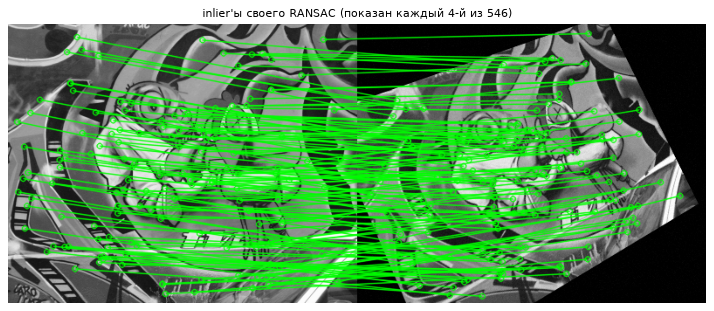

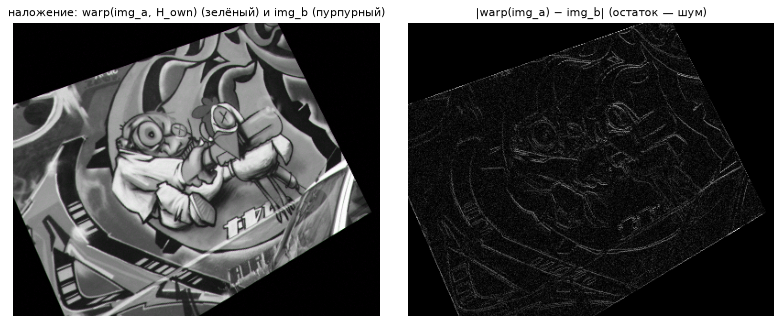

In [36]:
ka, kb = kp_to_cv(kp_a), kp_to_cv(kp_b)
dm = [cv2.DMatch(int(i), int(j), 0) for i, j in M_ratio]
sel = np.nonzero(mask_own)[0][::4]                       # каждый 4-й inlier, чтобы было видно линии
vis = cv2.drawMatches(img_a, ka, img_b, kb, [dm[i] for i in sel], None, matchColor=(0, 255, 0),
                      flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
show(vis, titles=[f"inlier'ы своего RANSAC (показан каждый 4-й из {mask_own.sum()})"], size=9)

warped = cv2.warpPerspective(img_a, H_own, (img_b.shape[1], img_b.shape[0]))
overlay = np.dstack([img_b, warped, img_b])                 # совпадение → серый, расхождение → цветное
diff = np.abs(warped.astype(int) - img_b.astype(int)).astype(np.uint8)
diff[warped == 0] = 0
show(overlay[..., ::-1], diff, titles=["наложение: warp(img_a, H_own) (зелёный) и img_b (пурпурный)",
                                       "|warp(img_a) − img_b| (остаток — шум)"], size=5)

### 7.1. Реальные пары: объект в сцене и смена ракурса

Здесь истинной гомографии нет — проверяем визуально: контур объекта, перенесённый найденной $H$.

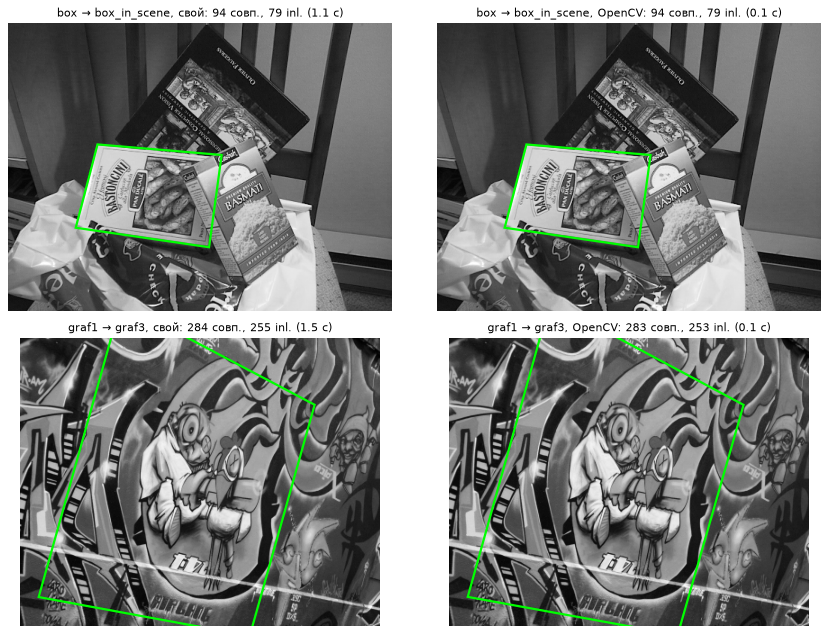

In [37]:
def locate(img1, img2, use_own=True, n_features=0):
    if use_own:
        k1, d1 = sift_detect_and_compute(img1, n_features)
        k2, d2 = sift_detect_and_compute(img2, n_features)
        p1, p2 = kp_xy(k1), kp_xy(k2)
        M, *_ = ratio_match(d1, d2, 0.8)
        H, mask, _ = ransac_homography(p1[M[:, 0]], p2[M[:, 1]], 3.0)
    else:
        k1, d1 = sift_cv.detectAndCompute(img1, None)
        k2, d2 = sift_cv.detectAndCompute(img2, None)
        p1, p2 = kp_xy(k1), kp_xy(k2)
        mm = [m for m, n in bf.knnMatch(d1, d2, k=2) if m.distance < 0.8 * n.distance]
        M = np.array([(m.queryIdx, m.trainIdx) for m in mm]).reshape(-1, 2)
        H, mask = cv2.findHomography(p1[M[:, 0]], p2[M[:, 1]], cv2.RANSAC, 3.0)
        mask = mask.ravel().astype(bool)
    return H, M, mask


graf1s = cv2.resize(graf1, (400, 320), interpolation=cv2.INTER_AREA)
graf3s = cv2.resize(graf3, (400, 320), interpolation=cv2.INTER_AREA)
fig, axs = plt.subplots(2, 2, figsize=(11, 8))
for row, (i1, i2, nm) in enumerate([(box, scene, "box → box_in_scene"), (graf1s, graf3s, "graf1 → graf3")]):
    for col, own in enumerate([True, False]):
        t = time.perf_counter()
        H, M, mask = locate(i1, i2, own)
        dt = time.perf_counter() - t
        h1, w1 = i1.shape
        cr = project(H, np.array([[0, 0], [w1 - 1, 0], [w1 - 1, h1 - 1], [0, h1 - 1]], float))
        axs[row, col].imshow(i2, cmap="gray")
        axs[row, col].add_patch(Polygon(cr, fill=False, color="lime", lw=2))
        axs[row, col].axis("off")
        axs[row, col].set_title(f"{nm}, {'свой' if own else 'OpenCV'}: {len(M)} совп., {mask.sum()} inl. ({dt:.1f} с)")
plt.tight_layout(); plt.show()

## 8. Оценка и эксперименты

На парах с известной $H$ считаем (ср. «Ключевые численные результаты» в [конспекте](../../rus/SIFT_конспект.md)):

* **повторяемость** — доля точек общей видимой области, у которых во втором изображении есть точка ближе $\varepsilon=3$ px
  после переноса $H$ (знаменатель — меньшее из чисел видимых точек);
* **precision** — доля верных среди принятых совпадений; **recall** — верные принятые / число точек, у которых
  вообще есть истинный партнёр;
* **доля inlier'ов** после RANSAC и **ошибка углов** найденной $H$.

In [38]:
# Код ниже совпадает с siftlab/evaluation.py (вставлен сборщиком tools/build_notebook.py)
def inside(p, w, h, margin=0):
    """Маска точек, лежащих внутри кадра w×h (с отступом margin)."""
    return (p[:, 0] >= margin) & (p[:, 0] <= w - 1 - margin) \
        & (p[:, 1] >= margin) & (p[:, 1] <= h - 1 - margin)


def repeatability(p1, p2, H, shape1, shape2, eps=3.0):
    """Повторяемость (упрощённо — только по положениям, без перекрытия областей).

    Берём точки общей видимой области. Точка «повторилась», если после переноса
    гомографией рядом (< eps px) есть точка другого изображения. Считаем в обе
    стороны (1→2 в пикселях img2, 2→1 в пикселях img1) и берём меньшее число,
    чтобы при сильном уменьшении несколько точек не засчитывались за одну.
    Делим на min(числа видимых точек) — как у Mikolajczyk et al."""
    h1, w1 = shape1[:2]
    h2, w2 = shape2[:2]
    q1 = project(H, p1)
    v1 = inside(q1, w2, h2)
    q2 = project(np.linalg.inv(H), p2)
    v2 = inside(q2, w1, h1)
    if v1.sum() == 0 or v2.sum() == 0:
        return 0.0

    def hits(a, b):
        d2 = (a * a).sum(1)[:, None] + (b * b).sum(1)[None] - 2 * a @ b.T
        return int((np.sqrt(np.maximum(d2.min(1), 0)) < eps).sum())

    n_rep = min(hits(q1[v1], p2[v2]), hits(q2[v2], p1[v1]))
    return float(n_rep / min(v1.sum(), v2.sum()))


def match_correctness(p1, p2, matches, H, thr=3.0):
    """Булев массив: совпадение (i, j) верно, если ‖H·p1[i] − p2[j]‖ < thr."""
    if len(matches) == 0:
        return np.zeros(0, bool)
    q = project(H, p1[matches[:, 0]])
    return np.linalg.norm(q - p2[matches[:, 1]], axis=1) < thr


def n_possible(p1, p2, H, thr=3.0):
    """Число точек img1, для которых в img2 есть истинный партнёр (ближе thr) — знаменатель recall."""
    q = project(H, p1)
    d2 = (q * q).sum(1)[:, None] + (p2 * p2).sum(1)[None] - 2 * q @ p2.T
    return int((np.sqrt(np.maximum(d2.min(1), 0)) < thr).sum())

свой SIFT    точек 1094/1030, повторяемость 0.646, @0.8: precision 0.938, recall 0.729, inlier'ов 0.938, ошибка углов 0.22 px
OpenCV SIFT  точек 1094/1030, повторяемость 0.646, @0.8: precision 0.938, recall 0.729, inlier'ов 0.938, ошибка углов 0.19 px
OpenCV ORB   точек 1482/1479, повторяемость 0.818, @0.8: precision 0.945, recall 0.530, inlier'ов 0.946, ошибка углов 1.20 px


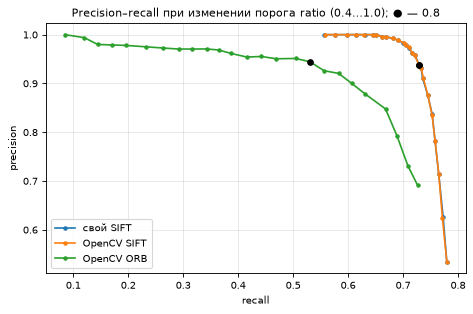

In [39]:
orb = cv2.ORB_create(nfeatures=1500)
bf_ham = cv2.BFMatcher(cv2.NORM_HAMMING)


def features(method, img, n=1500):
    if method == "свой SIFT":
        k, d = sift_detect_and_compute(img, n)
        return kp_xy(k), d
    det = cv2.SIFT_create(nfeatures=n) if method == "OpenCV SIFT" else orb
    k, d = det.detectAndCompute(img, None)
    return kp_xy(k), d


def knn_ratios(method, d1, d2):
    m = bf_ham if method == "OpenCV ORB" else bf
    kn = [x for x in m.knnMatch(d1, d2, k=2) if len(x) == 2]
    M = np.array([(a.queryIdx, a.trainIdx) for a, b in kn]).reshape(-1, 2)
    r = np.array([a.distance / max(b.distance, 1e-9) for a, b in kn])
    return M, r


METHODS = ["свой SIFT", "OpenCV SIFT", "OpenCV ORB"]
feats_a = {m: features(m, img_a) for m in METHODS}
fig, ax = plt.subplots(figsize=(6, 4))
for m in METHODS:
    p1, d1 = feats_a[m]
    p2, d2 = features(m, img_b)
    M, r = knn_ratios(m, d1, d2)
    ok = match_correctness(p1, p2, M, H_gt)
    npos = n_possible(p1, p2, H_gt)
    th = np.linspace(0.4, 1.0, 25)
    prec = [ok[r < t].mean() if (r < t).any() else 1 for t in th]
    rec = [ok[r < t].sum() / npos for t in th]
    ax.plot(rec, prec, ".-", label=m)
    j = np.argmin(np.abs(th - 0.8))
    ax.plot(rec[j], prec[j], "ko", ms=5)
    sel = r < 0.8
    Hm, mk = cv2.findHomography(p1[M[sel, 0]], p2[M[sel, 1]], cv2.RANSAC, 3.0)
    print(f"{m:<12} точек {len(p1)}/{len(p2)}, повторяемость {repeatability(p1, p2, H_gt, img_a.shape, img_b.shape):.3f}, "
          f"@0.8: precision {prec[j]:.3f}, recall {rec[j]:.3f}, inlier'ов {mk.mean():.3f}, "
          f"ошибка углов {corner_error(Hm, H_gt, 400, 320):.2f} px")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Precision–recall при изменении порога ratio (0.4…1.0); ● — 0.8")
plt.tight_layout(); plt.show()

### 8.1. Устойчивость к повороту и масштабу

Для каждого преобразования синтезируем $I_2 = \mathrm{warp}(I_1, H)$ (+шум σ=2) и считаем метрики для трёх методов:
свой SIFT, OpenCV SIFT и OpenCV ORB (бинарный дескриптор, расстояние Хэмминга; см. `../../rus/ORB_конспект.md`).
Число точек ограничено 1500 (для своего SIFT — top-N по отклику), ratio = 0.8, RANSAC — `cv2.findHomography`.
Гомография считается найденной, если ошибка углов < 5 px.

эксперименты: 11.2 с


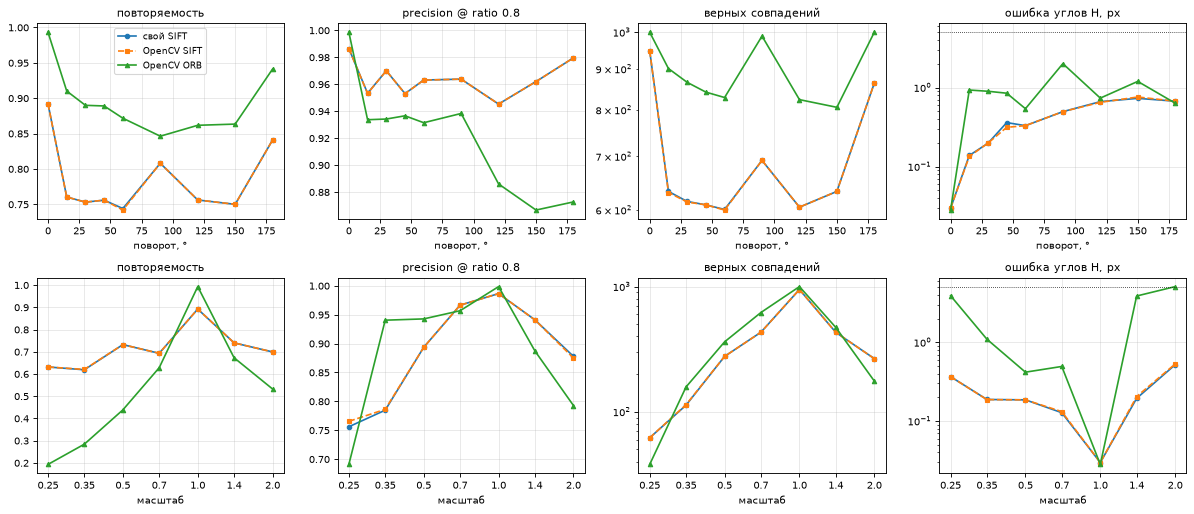

In [40]:
def evaluate(method, H, noise=2.0):
    img2 = make_pair(img_a, H, noise=noise)
    p1, d1 = feats_a[method]
    p2, d2 = features(method, img2)
    res = dict(rep=repeatability(p1, p2, H, img_a.shape, img2.shape), prec=0.0, ncorr=0, cerr=np.inf)
    if len(p2) < 2:
        return res
    M, r = knn_ratios(method, d1, d2)
    M = M[r < 0.8]
    ok = match_correctness(p1, p2, M, H)
    res.update(prec=ok.mean() if len(M) else 0.0, ncorr=int(ok.sum()))
    if len(M) >= 4:
        Hm, _ = cv2.findHomography(p1[M[:, 0]], p2[M[:, 1]], cv2.RANSAC, 3.0)
        res["cerr"] = corner_error(Hm, H, 400, 320) if Hm is not None else np.inf
    return res


angles = [0, 15, 30, 45, 60, 90, 120, 150, 180]
scales = [0.25, 0.35, 0.5, 0.7, 1.0, 1.4, 2.0]
t = time.perf_counter()
R_rot = {m: [evaluate(m, synthetic_homography(400, 320, angle=a)) for a in angles] for m in METHODS}
R_sc = {m: [evaluate(m, synthetic_homography(400, 320, scale=sc)) for sc in scales] for m in METHODS}
print(f"эксперименты: {time.perf_counter() - t:.1f} с")

fig, axs = plt.subplots(2, 4, figsize=(15, 6.5))
for row, (R, xs, xl) in enumerate([(R_rot, angles, "поворот, °"), (R_sc, scales, "масштаб")]):
    for col, (key, yl) in enumerate([("rep", "повторяемость"), ("prec", "precision @ ratio 0.8"),
                                     ("ncorr", "верных совпадений"), ("cerr", "ошибка углов H, px")]):
        ax = axs[row, col]
        for m, st in zip(METHODS, ["o-", "s--", "^-"]):
            ax.plot(xs, [min(v[key], 1e3) if v[key] > 0 else np.nan for v in R[m]], st, label=m, ms=4)
        ax.set_xlabel(xl); ax.set_title(yl); ax.grid(alpha=0.3)
        if row == 1:
            ax.set_xscale("log", base=2); ax.set_xticks(scales); ax.set_xticklabels(scales)
        if key == "cerr":
            ax.set_yscale("log"); ax.axhline(5, color="k", lw=0.7, ls=":")
        if key == "ncorr":
            ax.set_yscale("log")
axs[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [41]:
print(f"{'':<12}" + "".join(f"{a:>7}°" for a in angles))
for m in METHODS:
    print(f"{m:<12}" + "".join(f"{v['ncorr']:>8}" for v in R_rot[m]) + "   ← верных совпадений, поворот")
print(f"{'':<12}" + "".join(f"{sc:>8}" for sc in scales))
for m in METHODS:
    print(f"{m:<12}" + "".join(f"{v['ncorr']:>8}" for v in R_sc[m]) + "   ← верных совпадений, масштаб")

                  0°     15°     30°     45°     60°     90°    120°    150°    180°
свой SIFT        948     633     615     609     601     692     605     633     864   ← верных совпадений, поворот
OpenCV SIFT      948     631     614     609     600     692     605     633     864   ← верных совпадений, поворот
OpenCV ORB      1414     901     866     842     829     989     824     806    1234   ← верных совпадений, поворот
                0.25    0.35     0.5     0.7     1.0     1.4     2.0
свой SIFT         62     113     277     432     948     431     266   ← верных совпадений, масштаб
OpenCV SIFT       62     114     277     432     948     431     266   ← верных совпадений, масштаб
OpenCV ORB        38     158     362     621    1414     472     176   ← верных совпадений, масштаб


### 8.2. Откуда систематическая ошибка ~0.5 px при повороте?

Ошибка углов растёт с углом поворота даже без шума. Причина — смещение координат на +0.25 px от удвоения
`INTER_LINEAR` (раздел 3.1): при повороте на 180° смещения в двух изображениях направлены «в разные стороны»
относительно сцены и складываются в ~0.5 px. Проверим на OpenCV: средняя невязка $H\mathbf p_1 - \mathbf p_2$ по верным
совпадениям (без шума) с флагом `enable_precise_upscale` и без него.

In [42]:
for precise in (False, True):
    det = cv2.SIFT_create(enable_precise_upscale=precise)
    k1, d1 = det.detectAndCompute(img_a, None)
    for ang in (0, 90, 180):
        Hr = synthetic_homography(400, 320, angle=ang)
        k2, d2 = det.detectAndCompute(make_pair(img_a, Hr), None)
        mm = [m for m, n in bf.knnMatch(d1, d2, k=2) if m.distance < 0.8 * n.distance]
        p1, p2 = kp_xy(k1)[[m.queryIdx for m in mm]], kp_xy(k2)[[m.trainIdx for m in mm]]
        e = project(Hr, p1) - p2
        ok = np.linalg.norm(e, axis=1) < 3
        Hm, _ = cv2.findHomography(p1, p2, cv2.RANSAC, 3.0)
        print(f"precise_upscale={precise!s:<5} поворот {ang:>3}°: средняя невязка (x, y) = {e[ok].mean(0).round(3)} px, "
              f"ошибка углов H = {corner_error(Hm, Hr, 400, 320):.3f} px")

precise_upscale=False поворот   0°: средняя невязка (x, y) = [0. 0.] px, ошибка углов H = 0.000 px
precise_upscale=False поворот  90°: средняя невязка (x, y) = [ 0.006 -0.497] px, ошибка углов H = 0.504 px
precise_upscale=False поворот 180°: средняя невязка (x, y) = [-0.492 -0.504] px, ошибка углов H = 0.684 px
precise_upscale=True  поворот   0°: средняя невязка (x, y) = [0. 0.] px, ошибка углов H = 0.000 px
precise_upscale=True  поворот  90°: средняя невязка (x, y) = [0.002 0.002] px, ошибка углов H = 0.053 px
precise_upscale=True  поворот 180°: средняя невязка (x, y) = [ 0.001 -0.001] px, ошибка углов H = 0.039 px


**Что видно на графиках** (числа — из выполненного ноутбука; на вашей машине они должны совпасть, т.к. всё детерминировано).

* **Свой SIFT и OpenCV SIFT идут вплотную** во всех экспериментах: это одна и та же реализация. Различия в единицы
  совпадений — из-за `fastAtan2` и порядка отбора top-N.
* **Поворот.** Точность SIFT после ratio test 0.95–0.98 при любом угле. Число верных совпадений падает с ~950 (0°) до
  ~600–700 в основном потому, что при повороте кадра одинакового размера срезаются углы и общая область меньше, плюс
  интерполяция растра; при 90° и 180° поворот растра точный — совпадений больше. Ошибка $H$ растёт до ~0.7 px — это
  систематический сдвиг от удвоения (раздел 8.2), а не «неинвариантность».
* **Масштаб.** SIFT находит гомографию во всём диапазоне 0.25…2 (ошибка углов < 0.6 px), повторяемость держится на
  уровне 0.6–0.75. Число верных совпадений падает при уменьшении — у мелких деталей просто нет аналогов, а при ×2
  общая область — лишь центральная четверть кадра.
* **ORB** (1500 точек FAST против ~1100, которые SIFT находит на кадре 400×320) даёт *больше* верных совпадений при
  повороте и умеренном масштабе, но гомография по ним менее точна (0.5–2 px против 0.03–0.7 px у SIFT): угол — по
  центроиду интенсивности, положение — на уровне пикселя пирамиды без субпиксельного уточнения. На краях диапазона
  масштаба (0.25 и 2) повторяемость ORB падает до 0.2–0.5, а ошибка $H$ доходит до 4–5 px: пирамида ORB
  (8 уровней × 1.2 ≈ ×3.6) покрывает меньший диапазон, чем октавы SIFT.
* Значит, «SIFT лучше ORB» — не абсолютное утверждение: на этом текстурном изображении при небольших изменениях масштаба
  ORB конкурентоспособен и в десятки раз быстрее; преимущество SIFT — точность локализации и широкий диапазон масштабов.

## 9. Упражнения

1. **Число слоёв $s$ и σ.** Постройте пирамиду с $s=2, 4, 5$ и $\sigma_0 = 1.2, 2.0$. Как меняется число точек и
   повторяемость (раздел 8)? Сравните с рис. 3–4 статьи (разд. 3.2–3.3 [конспекта](../../rus/SIFT_конспект.md)).
   *Подсказка:* `sift_detect_and_compute(img, s=4)`; не забудьте, что порог контраста OpenCV-стиля — `0.04/s`.
2. **Порог контраста как в статье.** Задайте `contrast_thr=0.03` (и `cv2.SIFT_create(contrastThreshold=0.09)`). Сколько
   точек остаётся, как меняются precision/recall?
3. **Тест краёв.** Постройте зависимость числа точек и повторяемости от $r \in \{2, 5, 10, 20, 50\}$. Нарисуйте
   отброшенные «краевые» точки (`stats["rejected"]["edge"]`) — лежат ли они на контурах?
4. **RootSIFT.** Примените `root_sift` к дескрипторам обоих изображений и повторите кривую precision–recall
   из раздела 8. *Подсказка:* после RootSIFT расстояние L2 ≈ расстояние Хеллингера; ratio test работает так же.
5. **Размер сетки дескриптора.** Посчитайте дескрипторы с `d=2` и `d=8` (`compute_descriptors(kp, grads, d=...)`).
   Сравните с рис. 8 статьи (разд. 6.2): 4×4×8 — компромисс различимости и устойчивости.
   *Подсказка:* ширина окна растёт как $d\cdot3\sigma$ — при `d=8` точки у края будут обрезаны.
6. **Без ratio test.** Замените ratio test фиксированным порогом на $d_1$ (например, 0.3, 0.4, 0.5 для
   нормированных дескрипторов). Нарисуйте precision–recall и сравните с ratio test — почему глобальный порог хуже?
7. **Без трилинейной интерполяции / без обрезки 0.2.** Уберите распределение по соседним бинам (всё в ближайший)
   или поставьте `clip=1.0`. Как падает precision на паре с перспективой и шумом? На паре с изменением яркости
   (`img_b ** 0.5`)?
8. **Свои снимки.** Сделайте два снимка плоской сцены (страница книги, плакат) под разными углами, загрузите через
   `cv2.imread(..., cv2.IMREAD_GRAYSCALE)` и прогоните раздел 7.1. Для задачи позиционирования БПЛА возьмите пару
   надирных снимков с перекрытием (или снимок и ортофото): насколько хватает SIFT при сезонных изменениях?
   (см. «Значение для задачи визуального позиционирования» в [конспекте](../../rus/SIFT_конспект.md)).
9. **ORB vs SIFT на повороте.** Повторите раздел 8.1 для ORB с `WTA_K=3/4` и для `cv2.ORB_create(scaleFactor=1.1, nlevels=16)`.
   Где ORB догоняет SIFT, а где нет? Сравните время работы.
10. **Точный апсемплинг.** Сравните систематическое смещение координат (раздел 3.1) у `cv2.SIFT_create()` и
    `cv2.SIFT_create(enable_precise_upscale=True)` на синтетической паре со сдвигом на целое число пикселей.

## Проверка: код ноутбука = код пакета `siftlab`

Тот же конвейер из пакета `siftlab/` (его используют тесты) должен дать идентичный результат.

In [43]:
import importlib, siftlab
importlib.reload(siftlab)
k_pkg, d_pkg = siftlab.sift_detect_and_compute(box)
k_nb, d_nb = sift_detect_and_compute(box)
assert np.array_equal(kp_xy(k_pkg), kp_xy(k_nb)) and np.array_equal(d_pkg, d_nb)
print(f"OK: пакет и ноутбук совпадают ({len(d_nb)} точек на box.png)")
print(f"Время выполнения всего ноутбука: {time.time() - T_START:.0f} с")

OK: пакет и ноутбук совпадают (603 точек на box.png)
Время выполнения всего ноутбука: 30 с
